# ISE 518 – Assignment 3: Exploratory Data Analysis (EDA)
## Data-Driven Preventive Maintenance for Centrifugal-Pump Bearings Using Run-to-Failure Vibration and Temperature Data (KAIST benchmark)

**Course:** ISE 518 Data Analytics for Reliability and Maintenance (KFUPM) · **Group 6**
**Members:** Abdulaziz Alsaqer · Abdulkarim Musse · Ali Alabdrabareda · Mohammed Almatowa

---

### Objective of this notebook
Perform an exploratory data analysis of the project dataset in order to:
1. understand its **structure** (129 hourly vibration/temperature records of one ball bearing run to failure),
2. assess **data quality** (missing values, duplicates, outliers),
3. uncover **degradation patterns**, anomalies and potential biases,
4. identify **relationships** (features ↔ time / Remaining Useful Life) that matter for the later RUL-regression and PM-trigger models.

### Notebook road-map (follows the assignment instructions step-by-step)
| Step | Section |
|---|---|
| 0 | Problem recap and response to Assignment-2 feedback |
| 1 | Setup and data loading (read directly from the public URL) |
| 2 | Data cleaning (missing values, duplicates, z-score outliers) |
| 3 | Univariate analysis (numerical + categorical) |
| 4 | Multivariate analysis (correlation, significance tests, box/violin, OLS regression) |
| 5 | Time-series summarization and trend analysis (groupby, trends, `seasonal_decompose`, spectra) |
| 6 | Dashboard-style figure |
| 7 | Overall findings and implications for preprocessing, feature selection and modeling |
| 8 | AI use and reflection |

## 0. Problem Recap and Response to Assignment-2 Feedback

**Problem (from Assignment 2).** Centrifugal pumps are critical rotating assets in process industries, and rolling-bearing failures account for approximately **45–55 % of centrifugal-pump failure cases** [1]. A fixed preventive-maintenance (PM) interval creates two opposing risks: maintenance too early wastes useful bearing life, maintenance too late exposes the pump to unplanned failure and secondary damage. The project estimates bearing **Remaining Useful Life (RUL)** from vibration and temperature and converts it into a conservative PM trigger.

**Formulation (Assignment 2, Eqs. 1–4).** $RUL(t)=t_f-t$ (1); condition vector
$x(t)=[RMS_x,\ RMS_y,\ Peak,\ Kurtosis,\ Crest,\ T_b,\ T_b-T_{amb},\ dT_b/dt,\ dRMS/dt]$ (2); regression model $\widehat{RUL}=f(x)$ evaluated with MAE (3), RMSE, R²; PM trigger $t_{PM}=\min\{t: LB_{90\%}[\widehat{RUL}(t)]\le H\}$ (4), where $H$ = maintenance lead time + safety margin.
**This EDA computes every element of $x(t)$** and checks its quality, distribution and relationship with RUL before modeling.

**Why it matters (cost/downtime statistics – added after feedback).** The Siemens *True Cost of Downtime 2024* report [4] estimates that unplanned downtime costs the world's 500 largest companies about **US $1.4 trillion per year (≈11 % of their revenues)**, up from 8 % in 2019. A bearing that fails unexpectedly on a pump stops the process line, and secondary damage (seal, shaft, impeller rub) multiplies repair cost and mean-time-to-repair.

### How this assignment addresses the instructor's feedback on Assignment 2
| Feedback | Action taken in this project |
|---|---|
| *Title targets centrifugal pumps but data are from a single ball bearing.* | The scope is re-stated as **bearing-level prognostics for pump-drive rotating equipment**. The tested bearing (deep-groove ball bearing, NSK 6205 per dataset v6) is a size commonly used in small motors/pumps. Pump-specific effects (hydraulic loads, cavitation) are explicitly listed as *out of scope / noise* and as a transferability limitation. |
| *Only one statistic; no cost/downtime figures.* | Added the Siemens 2024 downtime-cost statistics (US $1.4 trillion/yr, 11 % of revenue, up from 8 % in 2019) in addition to the 45–55 % bearing share [1]. |
| *Formulation lacks noise/control factors (no P-diagram).* | A P-diagram table is given below; the EDA **quantifies** the ambient-temperature noise factor (Section 4.4 regression and Section 5.1 decomposition). |
| *One run-to-failure test → no population-level lifetime; plan to augment or add a 2nd dataset.* | (a) **Within-test augmentation:** each 78 s hourly record is split into many short windows → thousands of labelled samples along one degradation path. (b) **Second dataset plan:** add a public multi-bearing run-to-failure set (e.g. **XJTU-SY**, 15 bearings, or **FEMTO/PRONOSTIA**, 17 bearings) for population-level lifetime (Weibull / Kaplan–Meier) and cross-bearing validation. (c) EDA results are reported as *single-unit* evidence. |

### P-diagram (signal–response–control–noise)
| Element | Items |
|---|---|
| **Input signal** | Bearing vibration (x-, y-axis acceleration, 25.6 kHz), bearing temperature |
| **System** | Ball bearing under 2.94 kN axial + 5.88 kN radial load, ~1770–1780 rpm |
| **Intended response** | RUL (hours) / health index; PM trigger when the 90 % lower bound of RUL < lead-time |
| **Control factors** (we choose) | Window length, condition indicators (RMS, kurtosis, crest factor, …), smoothing, model type and hyper-parameters, alarm threshold, PM interval |
| **Noise factors** (we cannot control) | Ambient (atmospheric) temperature, speed fluctuation, sensor noise / mounting, lubrication & manufacturing variability between bearings, load fluctuations |

## 1. Setup and Data Loading

### 1.1 Import libraries
Libraries follow the course notebooks (`EDA.ipynb`, `TimeSeries_Analysis.ipynb`): **pandas, numpy, matplotlib, seaborn, scipy.stats, statsmodels**.

In [ ]:
# 📥 Import Required Libraries
import os, re, io, glob, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import zscore, skew, kurtosis, pearsonr, spearmanr, shapiro, mannwhitneyu
from scipy.signal import hilbert
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings('ignore')
sns.set(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 2.2.3 | seaborn 0.13.2


### 1.2 Dataset description
**Ball Bearing Vibration and Temperature Run-to-Failure Dataset** (KAIST; Jung et al. [2, 3]), Mendeley Data, DOI: [10.17632/5hcdd3tdvb.6](https://data.mendeley.com/datasets/5hcdd3tdvb/6), licence CC BY 4.0.

| Property | Value |
|---|---|
| Files | 129 CSV files, one per operating hour (`Vibration_Bearing_RuntoFailure.zip`, ≈4 GB) |
| Columns (each file) | `vibration (x-axis)`, `vibration (y-axis)`, `temperature (bearing)`, `temperature (Atmospheric)` |
| Sampling | 25.6 kHz, 78.125 s per file → 2,000,000 rows per file |
| Load | 300 kg (2.94 kN) axial, 600 kg (5.88 kN) vertical |
| Termination | bearing temperature > 85 °C **and** vibration > 9 m/s² |
| Failure | at ≈128 working hours |
| Speed | ≈1770–1780 rpm (v6), NSK 6205 deep-groove ball bearing |

**Data strategy (important).** 129 × 2 M rows ≈ 258 M rows does not fit comfortably in Colab memory. Each hourly file is therefore read **one at a time directly from the downloaded ZIP (no full extraction)** and reduced to a set of standard **condition indicators** (RMS, peak, kurtosis, …). The result is an *hourly feature table* (`df`, 129 rows) used for the EDA, plus a small **raw-signal table** (`df_raw`) holding the first hour, used for the signal-level checks. The feature table is cached to CSV so the notebook re-runs in seconds.

### 1.3 Configuration – choose how the data are read
| `DATA_SOURCE` | When to use |
|---|---|
| `'url'` **(default, reproducible)** | The notebook finds the ZIP on the public Mendeley repository and downloads it server-side into the Colab disk (`/content`, ≈ 100 GB free; ≈ 4 GB takes a few minutes – nothing passes through your own internet connection). |
| `'local_zip'` | The ZIP is already on the machine running the notebook (e.g. local Jupyter / VS Code, or a previous Colab download). |
| `'folder'` | The CSV files are already extracted in a folder (local Jupyter). |
| `'single_file'` | Quick test on ONE hourly CSV: the 78 s record is split into 1-s windows that play the role of "time steps". |

**How to run on the full 129 files (Google Colab):** `Runtime → Run all` with `DATA_SOURCE = 'url'`. The first run downloads ≈ 4 GB to the Colab disk and processes the files one by one (≈ 10–20 min in total, progress is printed); the result is cached in `kaist_hourly_features.csv`, so later runs in the same session take seconds. If the automatic link lookup fails, open the dataset page, start the download in your browser, copy the download address and paste it into `DIRECT_ZIP_URL`.

In [ ]:
# ===================== USER CONFIGURATION =====================
DATA_SOURCE = 'url'          # one of: 'url' | 'local_zip' | 'folder' | 'single_file'   (a mode name – NOT a link)

# --- 'url' option: public Mendeley dataset DOI 10.17632/5hcdd3tdvb.6 (resolved automatically) ---
MENDELEY_ID, MENDELEY_VERSION = '5hcdd3tdvb', 6
DIRECT_ZIP_URL = ''          # optional: paste a direct download link of the ZIP HERE (not in DATA_SOURCE) to skip the lookup

# --- 'local_zip' / 'folder' / 'single_file' options ---
LOCAL_ZIP_PATH  = 'Vibration_Bearing_RuntoFailure.zip'
CSV_FOLDER      = 'data'
SINGLE_FILE     = '/content/sample.csv'

# --- signal / machine parameters ---
FS          = 25_600         # sampling frequency [Hz]
RPM         = 1775           # shaft speed (dataset v6: 1770–1780 rpm; v2 states 3600 rpm – check your version)
VIB_UNIT    = 'm/s²'         # unit used by the dataset termination criterion
WINDOW_SEC  = 1.0            # window length for 'single_file' mode
CACHE_CSV   = 'kaist_hourly_features.csv'
LOCAL_ZIP   = '/content/kaist_bearing.zip' if os.path.isdir('/content') else 'kaist_bearing.zip'
COLS        = ['vib_x', 'vib_y', 'temp_bearing', 'temp_atm']   # standard short column names

### 1.4 Helper functions – download, read one hourly file, compute condition indicators
Condition indicators (CIs) computed per hour and per axis are the ones commonly used in bearing prognostics:

| CI | Formula / meaning |
|---|---|
| `rms` | $\sqrt{\frac1N\sum x_i^2}$ – vibration energy, grows with wear |
| `std` | standard deviation (energy without DC offset) |
| `peak`, `p2p` | $\max|x|$, $\max x-\min x$ – impacts |
| `crest` | peak / rms – impulsiveness (early spall) |
| `kurt` | 4th standardized moment (Fisher, normal = 0) – impulsiveness |
| `skew` | asymmetry |
| `centroid` | spectral centroid [Hz] – shift of energy to higher frequencies |
| `temp_rise`, `dTb_dt`, `dRMS_dt` | $T_b-T_{amb}$, temperature slope, RMS slope (added after loading) |

These indicators reproduce the **condition vector $x(t)$ of Assignment 2, Eq. (2)**: `vib_x_rms`=RMSx, `vib_y_rms`=RMSy, `vib_x_peak`=Peak, `vib_x_kurt`=Kurtosis, `vib_x_crest`=Crest, `temp_bearing`=T_b, `temp_rise`=T_b−T_amb, `dTb_dt`, `dRMS_dt`.

In [ ]:
def resolve_mendeley_zip_url(ds_id, version):
    # Find a public download link for the dataset ZIP (no login is needed for public Mendeley datasets).
    # 1) public Mendeley API (lists files with their download URLs); 2) Mendeley's "Download All" archive.
    import requests
    hdr = {'User-Agent': 'Mozilla/5.0', 'Accept': 'application/json'}
    for api in [f'https://data.mendeley.com/public-api/datasets/{ds_id}/files?folder_id=root&version={version}',
                f'https://data.mendeley.com/public-api/datasets/{ds_id}/files?version={version}']:
        try:
            files = requests.get(api, headers=hdr, timeout=60).json()
            for f in files:
                name = f.get('filename', '')
                print(f"  found: {name}  ({f.get('size', 0)/1e9:.2f} GB)")
                if name.lower().endswith('.zip'):
                    return f['content_details']['download_url']
        except Exception as e:
            print('  API lookup failed:', type(e).__name__)
    for fallback in [f'https://data.mendeley.com/public-api/zip/{ds_id}/download/{version}',
                     f'https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/{ds_id}-{version}.zip']:
        try:
            r = requests.head(fallback, headers=hdr, allow_redirects=True, timeout=60)
            if r.status_code == 200:
                print('  using Mendeley "Download All" archive:', fallback)
                return fallback
        except Exception as e:
            print('  fallback failed:', type(e).__name__)
    raise RuntimeError('Could not find the download link automatically – paste it into DIRECT_ZIP_URL.')

def download(url, dest, chunk=8 * 1024 * 1024):
    # Stream a large file to disk with a simple progress indicator (skips if a valid ZIP already exists).
    import requests
    if os.path.exists(dest) and zipfile.is_zipfile(dest):
        print('Already downloaded:', dest); return dest
    with requests.get(url, stream=True, timeout=120, headers={'User-Agent': 'Mozilla/5.0'}) as r:
        r.raise_for_status()
        total, done = int(r.headers.get('content-length', 0)), 0
        with open(dest, 'wb') as fh:
            for block in r.iter_content(chunk):
                fh.write(block); done += len(block)
                if total: print(f'\r  {done/1e9:.2f} / {total/1e9:.2f} GB', end='')
    if not zipfile.is_zipfile(dest):
        os.remove(dest)
        raise RuntimeError('Downloaded file is not a ZIP. Open https://data.mendeley.com/datasets/5hcdd3tdvb/6 , '
                           'start the download in your browser, copy the download link and paste it into DIRECT_ZIP_URL.')
    print('\nSaved to', dest); return dest

def natural_key(name):
    # Sort 'file_2.csv' before 'file_10.csv'.
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', os.path.basename(name))]

def read_signal(src):
    # Read one hourly CSV (path or file-like) into a float32 DataFrame with standard column names.
    df_ = pd.read_csv(src, low_memory=False)
    def _is_number(v):
        try: float(v); return True
        except (TypeError, ValueError): return False
    if any(_is_number(c) for c in df_.columns):                       # file without a header row
        src.seek(0) if hasattr(src, 'seek') else None
        df_ = pd.read_csv(src, header=None)
    df_ = df_.apply(pd.to_numeric, errors='coerce')
    if df_.shape[1] == 5 and df_.iloc[:, 0].is_monotonic_increasing:   # drop a time column if present
        df_ = df_.iloc[:, 1:]
    df_ = df_.iloc[:, :4].astype('float32')
    df_.columns = COLS
    return df_

def spectral_centroid(x, fs=FS):
    mag = np.abs(np.fft.rfft(x - x.mean()))
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return float((f * mag).sum() / mag.sum())

def condition_indicators(block):
    # Compute condition indicators for one record (an hour or a window). NaNs are ignored.
    out = {}
    for ax in ['vib_x', 'vib_y']:
        x = block[ax].dropna().to_numpy(dtype='float64')
        rms = np.sqrt(np.mean(x ** 2))
        peak = np.max(np.abs(x))
        out.update({f'{ax}_rms': rms, f'{ax}_std': x.std(), f'{ax}_peak': peak,
                    f'{ax}_p2p': x.max() - x.min(), f'{ax}_crest': peak / rms,
                    f'{ax}_kurt': kurtosis(x), f'{ax}_skew': skew(x),
                    f'{ax}_centroid': spectral_centroid(x)})
    out['temp_bearing'] = block['temp_bearing'].mean()
    out['temp_bearing_max'] = block['temp_bearing'].max()
    out['temp_atm'] = block['temp_atm'].mean()
    out['n_missing'] = int(block.isnull().sum().sum())
    out['n_samples'] = len(block)
    return out
print('Helper functions ready.')

Helper functions ready.


### 1.5 Load the data from the URL and build the hourly feature table
Every hourly file is streamed from the ZIP, summarized, and released from memory. The first hourly record is kept as `df_raw` for the raw-signal checks, and 1-s snippets of selected hours are kept in `snippets` for waveform / spectrum comparison in Section 5.

In [ ]:
t0 = time.time()
# --- guard against common configuration mistakes ---
if str(DATA_SOURCE).lower().startswith('http'):          # a link was pasted into DATA_SOURCE by mistake
    print('Note: DATA_SOURCE contains a link – using it as DIRECT_ZIP_URL with mode "url".')
    DIRECT_ZIP_URL, DATA_SOURCE = DATA_SOURCE, 'url'
assert DATA_SOURCE in ('url', 'local_zip', 'folder', 'single_file'), \
    f"DATA_SOURCE must be 'url', 'local_zip', 'folder' or 'single_file' – got {DATA_SOURCE!r}"
_ver = re.search(r'/download/(\d+)', DIRECT_ZIP_URL or '')
if _ver and _ver.group(1) != str(MENDELEY_VERSION):
    print(f'WARNING: the pasted link is for dataset version {_ver.group(1)}, but this project uses version '
          f'{MENDELEY_VERSION} (1770-1780 rpm). Use the version-{MENDELEY_VERSION} link for consistent results.')
snippets = {}            # hour -> first second of raw signal (for waveform/FFT plots)
SNIP = int(FS * 1.0)

def hourly_sources():
    # Yield (label, file-like) for each hourly CSV, according to DATA_SOURCE.
    if DATA_SOURCE in ('url', 'local_zip'):
        if DATA_SOURCE == 'url':
            url = DIRECT_ZIP_URL or resolve_mendeley_zip_url(MENDELEY_ID, MENDELEY_VERSION)
            zpath = download(url, LOCAL_ZIP)
        else:
            zpath = LOCAL_ZIP_PATH
        zf = zipfile.ZipFile(zpath)
        inner = [n for n in zf.namelist() if n.lower().endswith('.zip')]
        if inner and not any(n.lower().endswith('.csv') for n in zf.namelist()):
            # Mendeley "Download All" archives contain the data ZIP inside a ZIP → extract the inner ZIP to disk once
            big = max(inner, key=lambda n: zf.getinfo(n).file_size)
            inner_path = os.path.join(os.path.dirname(os.path.abspath(zpath)), os.path.basename(big))
            if not zipfile.is_zipfile(inner_path):
                print('Extracting inner archive', big, '...');
                with zf.open(big) as src_, open(inner_path, 'wb') as dst_:
                    while True:
                        b = src_.read(64 * 1024 * 1024)
                        if not b: break
                        dst_.write(b)
            zf = zipfile.ZipFile(inner_path)
        names = sorted([n for n in zf.namelist() if n.lower().endswith('.csv')], key=natural_key)
        print(f'{len(names)} CSV files in archive')
        for n in names:
            with zf.open(n) as fh:
                yield n, io.BytesIO(fh.read())
    elif DATA_SOURCE == 'folder':
        names = sorted(glob.glob(os.path.join(CSV_FOLDER, '**', '*.csv'), recursive=True), key=natural_key)
        print(f'{len(names)} CSV files in folder')
        for n in names:
            yield n, n

if os.path.exists(CACHE_CSV) and DATA_SOURCE != 'single_file':
    df = pd.read_csv(CACHE_CSV)
    snippets = {int(k): v for k, v in np.load(CACHE_CSV.replace('.csv', '_snips.npz')).items()}
    df_raw = pd.read_pickle(CACHE_CSV.replace('.csv', '_raw.pkl')) if os.path.exists(CACHE_CSV.replace('.csv', '_raw.pkl')) else None
    TIME_UNIT = 'hour'
    print('Loaded cached feature table:', df.shape)
elif DATA_SOURCE == 'single_file':
    # Quick-test mode: one hourly CSV/XLSX split into consecutive windows treated as time steps.
    df_raw = pd.read_excel(SINGLE_FILE) if SINGLE_FILE.endswith(('xls', 'xlsx')) else read_signal(SINGLE_FILE)
    if SINGLE_FILE.endswith(('xls', 'xlsx')):
        df_raw = df_raw.select_dtypes('number').iloc[:, :4].astype('float32'); df_raw.columns = COLS
    w = int(FS * WINDOW_SEC)
    rows = []
    for k, start in enumerate(range(0, len(df_raw) - w + 1, w)):
        blk = df_raw.iloc[start:start + w]
        rows.append({'hour': k, **condition_indicators(blk)})
        if k % max(1, (len(df_raw) // w) // 6) == 0:
            snippets[k] = blk.iloc[:SNIP][['vib_x', 'vib_y']].to_numpy()
    df = pd.DataFrame(rows)
    TIME_UNIT = f'window ({WINDOW_SEC:g} s)'
else:
    rows, df_raw = [], None
    for k, (name, src) in enumerate(hourly_sources()):
        sig = read_signal(src)
        if df_raw is None:
            df_raw = sig.copy()                       # keep the first hour for raw-level EDA
        rows.append({'hour': k, 'file': os.path.basename(name), **condition_indicators(sig)})
        snippets[k] = sig.iloc[:SNIP][['vib_x', 'vib_y']].to_numpy()
        if k % 10 == 0:
            print(f'  processed hour {k:3d}  ({time.time()-t0:5.0f} s)')
        del sig, src
    if not rows:
        raise RuntimeError('No CSV files were read – check DATA_SOURCE / DIRECT_ZIP_URL / folder path.')
    df = pd.DataFrame(rows)
    TIME_UNIT = 'hour'
    # keep only ~7 snippets (memory) and cache everything for fast re-runs
    keep = sorted(set(np.linspace(0, df['hour'].max(), 6).astype(int)) | {int(df['hour'].max()) - 2})
    snippets = {k: snippets[k] for k in keep}
    df.to_csv(CACHE_CSV, index=False)
    np.savez(CACHE_CSV.replace('.csv', '_snips.npz'), **{str(k): v for k, v in snippets.items()})
    df_raw.to_pickle(CACHE_CSV.replace('.csv', '_raw.pkl'))

# Target variable – Eq. (1): RUL(t) = t_f − t  (time units until the last record = end-of-life)
df['RUL'] = df['hour'].max() - df['hour']

# Remaining elements of the Assignment-2 condition vector x(t), Eq. (2)
df['temp_rise'] = df['temp_bearing'] - df['temp_atm']                    # T_b − T_amb (ambient-corrected)
df['dTb_dt']    = df['temp_bearing'].diff().fillna(0)                   # temperature slope [°C per step] (0 at start)
df['dRMS_dt']   = df['vib_x_rms'].diff().fillna(0)                       # vibration-energy slope [per step]
print(f'Feature table built: {df.shape}  | time unit = {TIME_UNIT} | elapsed {time.time()-t0:.0f} s')

  found: Vibration_Bearing_RuntoFailure.zip  (4.33 GB)
  4.33 / 4.33 GB
Saved to /content/kaist_bearing.zip
129 CSV files in archive
  processed hour   0  (  130 s)
  processed hour  10  (  188 s)
  processed hour  20  (  247 s)
  processed hour  30  (  304 s)
  processed hour  40  (  367 s)
  processed hour  50  (  429 s)
  processed hour  60  (  485 s)
  processed hour  70  (  541 s)
  processed hour  80  (  599 s)
  processed hour  90  (  669 s)
  processed hour 100  (  729 s)
  processed hour 110  (  788 s)
  processed hour 120  (  847 s)
Feature table built: (129, 27)  | time unit = hour | elapsed 894 s


### 1.6 First look: `head()`, `info()`, `describe()`
**(a) Raw signal table (first hourly file)**

In [ ]:
if df_raw is not None:
    print('Raw table shape:', df_raw.shape, '→', f'{len(df_raw)/FS:.3f} s of signal at {FS} Hz')
    display(df_raw.head())
    df_raw.info()
    display(df_raw.describe().T)

Raw table shape: (2000001, 4) → 78.125 s of signal at 25600 Hz


,vib_x,vib_y,temp_bearing,temp_atm
0,0.0486,-0.0638,41.6149,24.8174
1,-0.1176,-0.3782,41.6149,24.8174
2,-0.1258,-0.4478,41.6149,24.8174
3,0.1747,-0.2014,41.6149,24.8174
4,0.2987,-0.0939,41.6149,24.8174


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000001 entries, 0 to 2000000
Data columns (total 4 columns):
 #   Column        Dtype  
---  ------        -----  
 0   vib_x         float32
 1   vib_y         float32
 2   temp_bearing  float32
 3   temp_atm      float32
dtypes: float32(4)
memory usage: 30.5 MB


,count,mean,std,min,25%,50%,75%,max
vib_x,"1,999,961.0000",0.0079,0.3708,-2.2359,-0.2160,0.0198,0.2460,2.0857
vib_y,"1,999,961.0000",0.0171,0.5925,-3.6181,-0.3532,0.0192,0.3898,3.8715
temp_bearing,"1,999,919.0000",41.8236,1.0730,41.6034,41.7095,41.8058,41.9479,42.0494
temp_atm,"1,999,919.0000",24.8460,0.5641,24.6775,24.7769,24.8375,24.9219,24.9952


**(b) Hourly condition-indicator table (one row per hour of the test)**

In [ ]:
display(df.head())
df.info()
display(df.describe().T)

,hour,file,vib_x_rms,vib_x_std,vib_x_peak,vib_x_p2p,vib_x_crest,vib_x_kurt,vib_x_skew,vib_x_centroid,...,vib_y_centroid,temp_bearing,temp_bearing_max,temp_atm,n_missing,n_samples,RUL,temp_rise,dTb_dt,dRMS_dt
0,0,LogFile_2022-06-20-17-00-31.csv,0.3712,0.3711,2.2359,4.3216,6.0235,0.8632,-0.2188,"3,877.2140",...,"3,908.3872",41.8236,42.0494,24.8460,244,2000001,128,16.9776,0.0000,0.0000
1,1,LogFile_2022-06-20-18-00-31.csv,0.3658,0.3657,2.8605,5.0686,7.8191,1.3102,-0.2284,"3,828.7800",...,"3,837.7345",31.6850,32.1529,24.7835,244,2000001,127,6.9015,-10.1386,-0.0054
2,2,LogFile_2022-06-20-19-00-31.csv,0.3640,0.3639,2.5792,5.0879,7.0861,0.9877,-0.1372,"3,805.7438",...,"3,833.6759",30.6104,31.0791,24.8468,244,2000001,126,5.7636,-1.0745,-0.0019
3,3,LogFile_2022-06-20-20-00-31.csv,0.3850,0.3849,2.4619,4.7687,6.3941,1.0192,-0.3085,"3,869.6459",...,"3,927.0912",32.6612,33.2229,25.3438,244,2000001,125,7.3175,2.0508,0.0210
4,4,LogFile_2022-06-20-21-00-31.csv,0.3759,0.3758,2.1948,4.3716,5.8381,0.9607,-0.2195,"3,813.6583",...,"3,850.5463",33.9270,34.4370,25.2757,244,2000001,124,8.6513,1.2658,-0.0091


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 27 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hour              129 non-null    int64  
 1   file              129 non-null    object 
 2   vib_x_rms         129 non-null    float64
 3   vib_x_std         129 non-null    float64
 4   vib_x_peak        129 non-null    float64
 5   vib_x_p2p         129 non-null    float64
 6   vib_x_crest       129 non-null    float64
 7   vib_x_kurt        129 non-null    float64
 8   vib_x_skew        129 non-null    float64
 9   vib_x_centroid    129 non-null    float64
 10  vib_y_rms         129 non-null    float64
 11  vib_y_std         129 non-null    float64
 12  vib_y_peak        129 non-null    float64
 13  vib_y_p2p         129 non-null    float64
 14  vib_y_crest       129 non-null    float64
 15  vib_y_kurt        129 non-null    float64
 16  vib_y_skew        129 non-null    float64
 1

,count,mean,std,min,25%,50%,75%,max
hour,129.0000,64.0000,37.3832,0.0000,32.0000,64.0000,96.0000,128.0000
vib_x_rms,129.0000,0.3714,0.2041,0.2641,0.3137,0.3307,0.3604,1.6374
vib_x_std,129.0000,0.3714,0.2041,0.2640,0.3136,0.3307,0.3603,1.6374
vib_x_peak,129.0000,3.3598,6.6814,1.5213,1.9196,2.0939,2.2703,51.0224
vib_x_p2p,129.0000,5.7532,9.8179,2.8341,3.6535,4.0490,4.3813,90.7176
vib_x_crest,129.0000,7.0723,4.2578,4.9418,5.9447,6.2337,6.5577,38.8069
vib_x_kurt,129.0000,3.4898,23.1811,-0.0936,0.8535,1.0836,1.2862,258.5196
vib_x_skew,129.0000,-0.1234,1.2083,-2.4803,-0.3085,-0.2112,-0.0883,13.1951
vib_x_centroid,129.0000,"3,905.6018",161.0384,"3,288.3188","3,826.8546","3,872.0495","3,987.6665","4,857.0014"
vib_y_rms,129.0000,0.6322,0.1663,0.4416,0.5358,0.6180,0.6832,1.6393


#### 📝 Key findings – structure
* **All 129 hourly files were read** (`LogFile_2022-06-20-17-00-31.csv` → `LogFile_2022-06-26-01-00-31.csv`, one file per operating hour). Each file has **2,000,001 rows × 4 numerical columns** (78.125 s × 25.6 kHz, plus one sample), stored as `float32` (30.5 MB per hour in memory, ≈ 258 M rows in total).
* The raw data are **four continuous numerical signals** – there are **no native categorical variables** and no explicit time column inside the files; time comes from the file time stamp (hour) and the sample index (1/25 600 s).
* **First hour (healthy bearing):** vibration x has std ≈ 0.37 m/s² (range −2.24 … 2.09), vibration y is larger (std ≈ 0.59 m/s², range −3.62 … 3.87) → the two axes have different sensitivity / load direction. Bearing temperature ≈ 41.6–42.0 °C and ambient ≈ 24.7–25.0 °C during that hour.
* The **hourly feature table** has 129 rows × 27 columns (16 vibration indicators, 3 temperatures, the Eq. (2) slopes, bookkeeping columns and the target **RUL = 128 − hour**).
* *Implication:* the modeling dataset is **small in rows (129) but rich in signal** → windowing each hour into 1-s segments (≈ 78 per hour, ≈ 10 000 samples) is needed for RUL models (augmentation, Section 0).

## 2. Data Cleaning
### 2.1 Missing values and duplicates

In [ ]:
# Missing values
if df_raw is not None:
    print('Missing values – raw signal (first hour):'); print(df_raw.isnull().sum(), '\n')
print('Missing values – hourly table:'); print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().any() else '  none')
print('Total missing raw samples summed over all hours:', int(df['n_missing'].sum()))

# Duplicates
if df_raw is not None:
    print('\nDuplicate rows – raw signal:', df_raw.duplicated().sum(),
          f'({df_raw.duplicated().mean()*100:.2f} % of rows)')
print('Duplicate rows – hourly table:', df.drop(columns=['file'], errors='ignore').duplicated().sum())
# Record-length check: every hour should contain the same number of samples (78.125 s × 25.6 kHz)
print('\nSamples per record (should be constant):'); print(df['n_samples'].value_counts())
print(f"Missing raw samples per hour: mean={df['n_missing'].mean():.0f}, max={df['n_missing'].max()} "
      f"→ {df['n_missing'].sum() / df['n_samples'].sum() * 100:.4f} % of raw rows (≈ ¼ of that per value, 4 channels)")

# Time-axis check: file names carry the acquisition time stamp (LogFile_YYYY-MM-DD-HH-MM-SS.csv)
if 'file' in df.columns:
    df['timestamp'] = pd.to_datetime(df['file'].str.extract(r'(\d{4}-\d{2}-\d{2}-\d{2}-\d{2}-\d{2})')[0],
                                     format='%Y-%m-%d-%H-%M-%S', errors='coerce')
if 'timestamp' in df.columns and df['timestamp'].notna().all():
    gaps = df['timestamp'].diff().dropna().value_counts()
    print(f"\nFirst record: {df['timestamp'].iloc[0]}   Last record: {df['timestamp'].iloc[-1]}")
    print('Spacing between consecutive files (should be 1 hour everywhere):'); print(gaps)
    df['clock_hour'] = df['timestamp'].dt.hour
else:
    df['clock_hour'] = df['hour'] % 24

Missing values – raw signal (first hour):
vib_x           40
vib_y           40
temp_bearing    82
temp_atm        82
dtype: int64 

Missing values – hourly table:
  none
Total missing raw samples summed over all hours: 33874

Duplicate rows – raw signal: 39 (0.00 % of rows)
Duplicate rows – hourly table: 0

Samples per record (should be constant):
n_samples
2000001    129
Name: count, dtype: int64
Missing raw samples per hour: mean=263, max=324 → 0.0131 % of raw rows (≈ ¼ of that per value, 4 channels)

First record: 2022-06-20 17:00:31   Last record: 2022-06-26 01:00:31
Spacing between consecutive files (should be 1 hour everywhere):
timestamp
0 days 01:00:00    124
0 days 01:01:00      2
0 days 01:12:00      1
0 days 00:46:00      1
Name: count, dtype: int64


### 2.2 Handle missing values and duplicates
* **Hourly features:** any missing value is imputed with the **median** (robust to the large late-life values).
* **Raw signal:** if gaps exist they are filled with **linear interpolation** – for a 25.6 kHz signal the neighbour samples are a far better estimate than a global mean.
* **Duplicates:** in the hourly table a duplicate would indicate a file read twice → removed. In the raw table identical rows are *expected* (quantised sensor values repeat) and are **not** removed, because each row is a distinct time instant; deleting them would distort the time axis and the spectrum.

In [ ]:
num_cols_all = df.select_dtypes('number').columns.drop(['hour', 'RUL', 'n_missing', 'n_samples'])
n_before = df.isnull().sum().sum()
df[num_cols_all] = df[num_cols_all].fillna(df[num_cols_all].median())          # median imputation
df = df.drop_duplicates(subset=[c for c in df.columns if c != 'file']).reset_index(drop=True)
if df_raw is not None and df_raw.isnull().any().any():
    df_raw = df_raw.interpolate(method='linear', limit_direction='both')        # time-series imputation
print(f'Imputed {n_before} missing hourly values; remaining missing: {df.isnull().sum().sum()}')

Imputed 0 missing hourly values; remaining missing: 0


### 2.3 Outlier detection with `scipy.stats.zscore`
Outliers are flagged where $|z| > 3$. Two levels are checked:
* **Raw signal (first hour)** – spikes that may be sensor glitches.
* **Hourly features** – hours that deviate strongly from the overall behaviour.

As in the course anomaly-detection notebook, the z-score is compared with the robust **IQR** rule.

In [ ]:
# --- Raw level ---
if df_raw is not None:
    z_raw = np.abs(np.asarray(zscore(df_raw, nan_policy='omit')))
    out_raw = pd.Series((z_raw > 3).sum(axis=0), index=COLS)
    print('Raw-signal samples with |z| > 3 (first hour):')
    print(pd.DataFrame({'n_outliers': out_raw, 'percent': out_raw / len(df_raw) * 100}).round(3))

# --- Hourly level ---
feat_cols = [c for c in num_cols_all if c not in ['temp_bearing_max']]
z_h = pd.DataFrame(np.abs(zscore(df[feat_cols])), columns=feat_cols)
q1, q3 = df[feat_cols].quantile(0.25), df[feat_cols].quantile(0.75)
iqr_flag = (df[feat_cols] < q1 - 1.5 * (q3 - q1)) | (df[feat_cols] > q3 + 1.5 * (q3 - q1))
outlier_tbl = pd.DataFrame({'z>3 count': (z_h > 3).sum(), 'IQR count': iqr_flag.sum(),
                            f'first {TIME_UNIT} flagged (z>3)': [df.loc[z_h[c] > 3, 'hour'].min() for c in feat_cols]})
display(outlier_tbl)
df['any_outlier_z'] = (z_h > 3).any(axis=1)
print(f"{TIME_UNIT}s flagged as outliers by z-score:", df.loc[df['any_outlier_z'], 'hour'].tolist())

Raw-signal samples with |z| > 3 (first hour):
              n_outliers  percent
vib_x              16345   0.8170
vib_y              15347   0.7670
temp_bearing           0   0.0000
temp_atm               0   0.0000


,z>3 count,IQR count,first hour flagged (z>3)
vib_x_rms,5,5,124.0000
vib_x_std,5,5,124.0000
vib_x_peak,4,8,124.0000
vib_x_p2p,4,6,124.0000
vib_x_crest,4,9,124.0000
vib_x_kurt,1,5,124.0000
vib_x_skew,1,3,124.0000
vib_x_centroid,4,7,120.0000
vib_y_rms,3,4,126.0000
vib_y_std,3,4,126.0000


hours flagged as outliers by z-score: [1, 120, 121, 124, 125, 126, 127, 128]


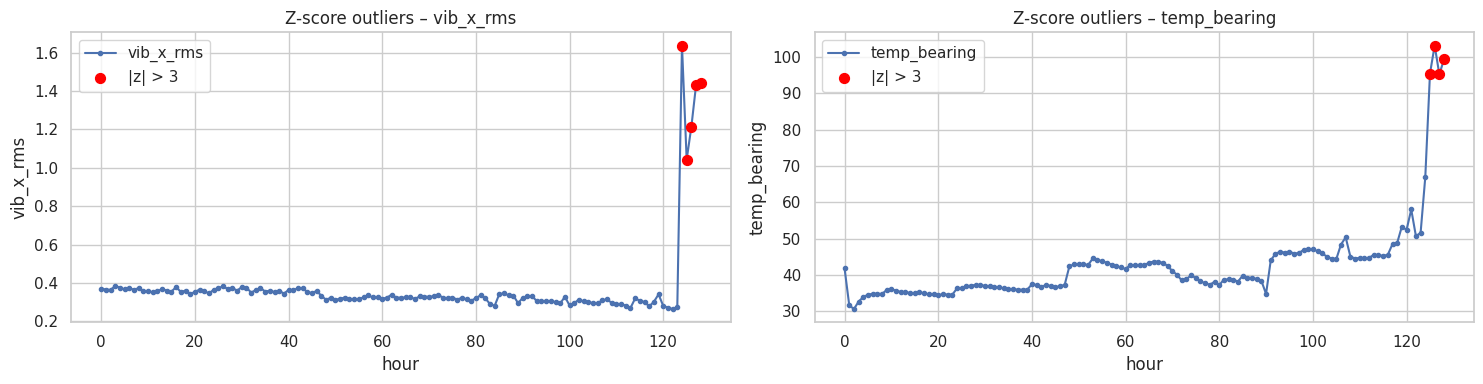

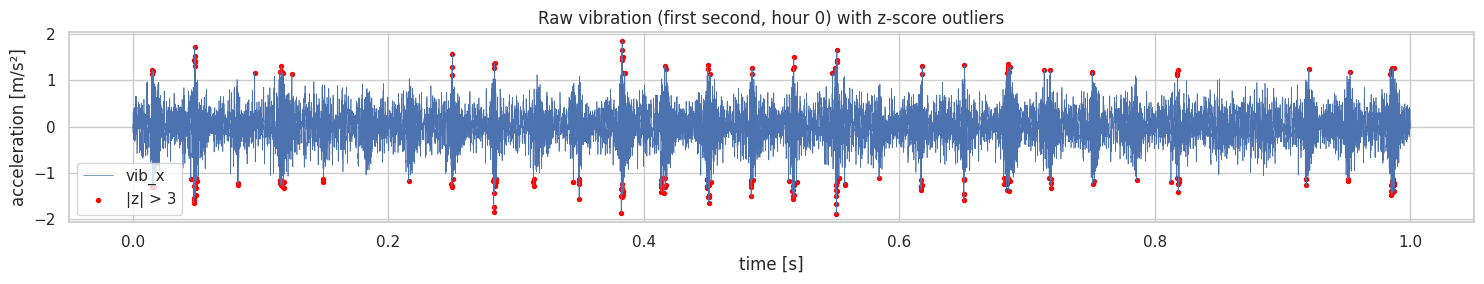

In [ ]:
# Visualise where the z-score outliers occur along the test (are they random or at the end of life?)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, col in zip(axes, ['vib_x_rms', 'temp_bearing']):
    ax.plot(df['hour'], df[col], marker='.', label=col)
    m = z_h[col] > 3
    ax.scatter(df.loc[m, 'hour'], df.loc[m, col], color='red', s=50, zorder=3, label='|z| > 3')
    ax.set_title(f'Z-score outliers – {col}'); ax.set_xlabel(TIME_UNIT); ax.set_ylabel(col); ax.legend()
plt.tight_layout(); plt.show()

if df_raw is not None:   # raw spikes in the first second of the first hour
    seg = df_raw.iloc[:FS]; zseg = np.abs(zscore(seg['vib_x']))
    plt.figure(figsize=(15, 3))
    t = np.arange(len(seg)) / FS
    plt.plot(t, seg['vib_x'], lw=0.5, label='vib_x')
    plt.scatter(t[zseg > 3], seg['vib_x'][zseg > 3], color='red', s=8, label='|z| > 3')
    plt.title('Raw vibration (first second, hour 0) with z-score outliers'); plt.xlabel('time [s]'); plt.ylabel(f'acceleration [{VIB_UNIT}]')
    plt.legend(); plt.tight_layout(); plt.show()

#### 📝 Key findings – data quality
* **Completeness:** all 129 files were read and **every hour has exactly 2,000,001 samples**. The acquisition runs from 20 June 2022 17:00 to 26 June 2022 01:00. File spacing is 1 h for 124 intervals; two intervals are 1 h 01 min and one 1 h 12 min immediately followed by one of 46 min (a delayed recording that the logger made up) → using the file index as "operating hour" introduces at most ≈ 12 min error, which is negligible for a 128-h life.
* **Missing values:** only **33,874 raw values are missing in total (mean 263, max 324 per hour)**; the printed 0.0131 % refers to the number of raw rows – relative to all 4 channels it is ≈ 0.003 % of all values. In the first hour 40 values per vibration channel and 82 per temperature channel are missing. They were linearly interpolated in the raw table and ignored (`dropna`) in the hourly indicators → no effect. The hourly table has **no missing values**, so median imputation changed nothing (0 values imputed).
* **Duplicates:** 39 identical raw rows (0.002 %) – repeated quantised sensor values, **not** data-entry errors, so they are kept (removing them would break the 25.6 kHz time axis). The hourly table has **0 duplicates**.
* **Raw outliers:** 0.82 % (x) and 0.77 % (y) of the healthy-hour vibration samples have |z| > 3, about **3× the 0.27 % expected for a Gaussian signal** → healthy vibration already has heavy tails (kurtosis ≈ 0.86, normal = 0), i.e. normal mechanical impacts, not sensor faults. Temperatures have no raw outliers.
* **Hourly outliers (z-score) occur at hours 1, 120, 121 and 124–128.** Hour 1 is flagged only by the temperature slope `dTb_dt` (−10.1 °C): a **start-up transient** (41.8 °C in hour 0 → 31.7 °C in hour 1). All other outliers are in the **final hours** (vibration RMS: 5 hours, first at hour 124; bearing temperature: 4 hours, first at hour 125); the IQR rule flags a few more hours, mostly in the same late period. (`clock_hour` appears in the table only as a bookkeeping column – 0 outliers.)
* **Decision:** the late outliers are the **failure signature, not errors**, so they are **kept**; the start-up hour is excluded from baselines (Section 3.3). Because the indicators are strongly non-normal (Section 3), a whole-life z-score is a weak alarm rule; a **baseline-referenced** limit is used instead.
* *Implication for preprocessing:* no row deletion; robust scaling / baseline normalisation; log-transform energy features; treat the start-up hour separately.

## 3. Univariate Analysis
### 3.1 Numerical variables – summary statistics (pandas + `scipy.stats`)

In [ ]:
key_num = ['vib_x_rms', 'vib_y_rms', 'vib_x_peak', 'vib_x_kurt', 'vib_x_crest',
           'vib_x_centroid', 'temp_bearing', 'temp_atm', 'temp_rise', 'dTb_dt', 'dRMS_dt']
summary = pd.DataFrame({
    'mean':   df[key_num].mean(),
    'median': df[key_num].median(),
    'std':    df[key_num].std(),
    'min':    df[key_num].min(),
    'max':    df[key_num].max(),
    'skew':   [skew(df[c]) for c in key_num],          # scipy.stats
    'kurtosis': [kurtosis(df[c]) for c in key_num],    # scipy.stats (Fisher, normal = 0)
    'Shapiro p': [shapiro(df[c])[1] for c in key_num], # normality test (L3)
    'CV %':   df[key_num].std() / df[key_num].mean() * 100,
})
display(summary)
print(stats.describe(df['vib_x_rms']))   # scipy.stats one-shot summary for the main health indicator

,mean,median,std,min,max,skew,kurtosis,Shapiro p,CV %
vib_x_rms,0.3714,0.3307,0.2041,0.2641,1.6374,4.9100,23.5345,0.0000,54.9598
vib_y_rms,0.6322,0.6180,0.1663,0.4416,1.6393,3.4420,16.6936,0.0000,26.3045
vib_x_peak,3.3598,2.0939,6.6814,1.5213,51.0224,5.4793,30.2212,0.0000,198.8613
vib_x_kurt,3.4898,1.0836,23.1811,-0.0936,258.5196,10.5444,112.5850,0.0000,664.2581
vib_x_crest,7.0723,6.2337,4.2578,4.9418,38.8069,5.6221,33.0264,0.0000,60.2035
vib_x_centroid,"3,905.6018","3,872.0495",161.0384,"3,288.3188","4,857.0014",1.5650,10.8993,0.0000,4.1233
temp_bearing,42.5452,39.7711,11.4438,30.6104,103.1004,3.6756,15.3142,0.0000,26.8980
temp_atm,25.4934,25.5670,0.5122,24.5173,26.6469,0.1899,-0.3753,0.0030,2.0092
temp_rise,17.0518,14.0117,11.1398,5.7636,76.4535,3.7629,15.8866,0.0000,65.3292
dTb_dt,0.4457,-0.0424,3.5312,-10.1386,28.4569,4.3116,32.3447,0.0000,792.3045


DescribeResult(nobs=np.int64(129), minmax=(np.float64(0.2640938558356704), np.float64(1.6374143964130605)), mean=np.float64(0.37143545485088403), variance=np.float64(0.04167323368461329), skewness=np.float64(4.910021303469181), kurtosis=np.float64(23.53451126255157))


### 3.2 Numerical variables – distributions (histograms with KDE and box plots)

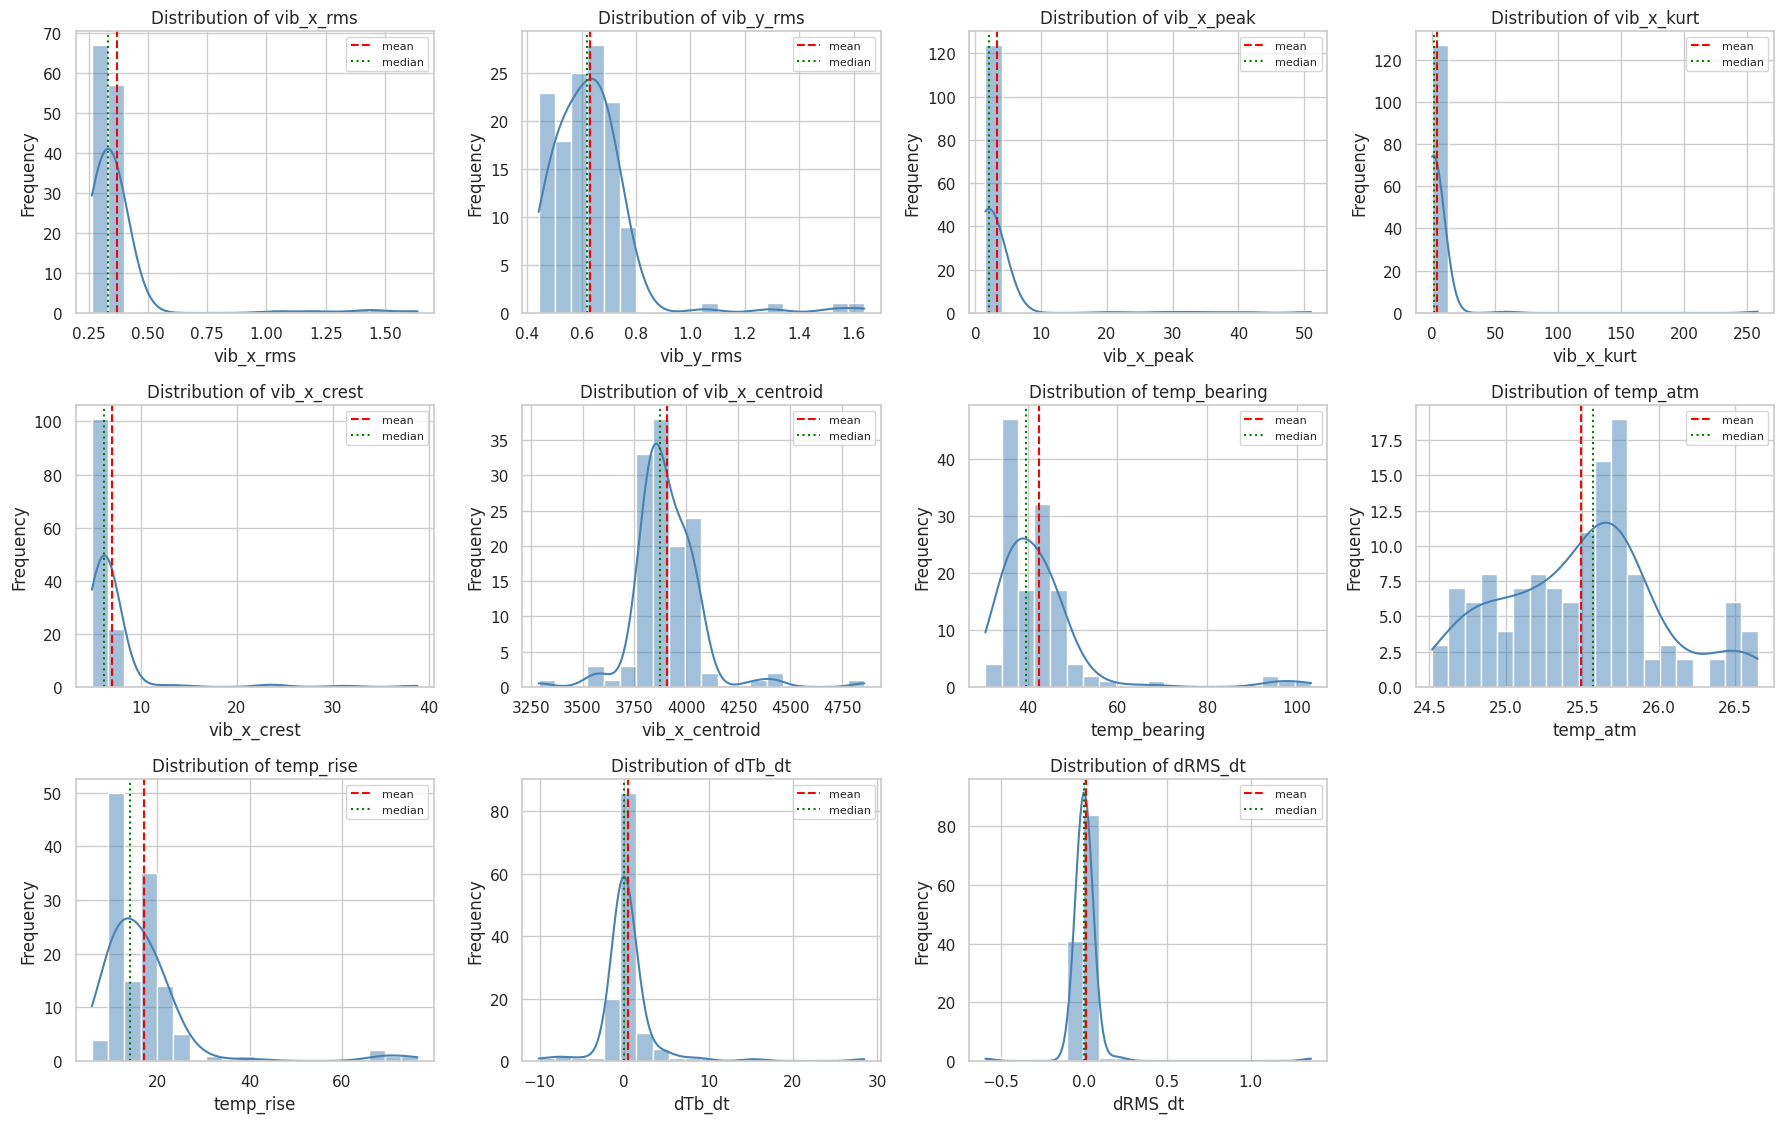

In [ ]:
n_cols = 4
n_rows = int(np.ceil(len(key_num) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.8))
axes = axes.flatten()
for i, col in enumerate(key_num):
    sns.histplot(df[col], kde=True, bins=20, ax=axes[i], color='steelblue')
    axes[i].axvline(df[col].mean(), color='red', ls='--', label='mean')
    axes[i].axvline(df[col].median(), color='green', ls=':', label='median')
    axes[i].set_title(f'Distribution of {col}'); axes[i].set_xlabel(col); axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)
for j in range(i + 1, len(axes)): axes[j].axis('off')
plt.tight_layout(); plt.show()

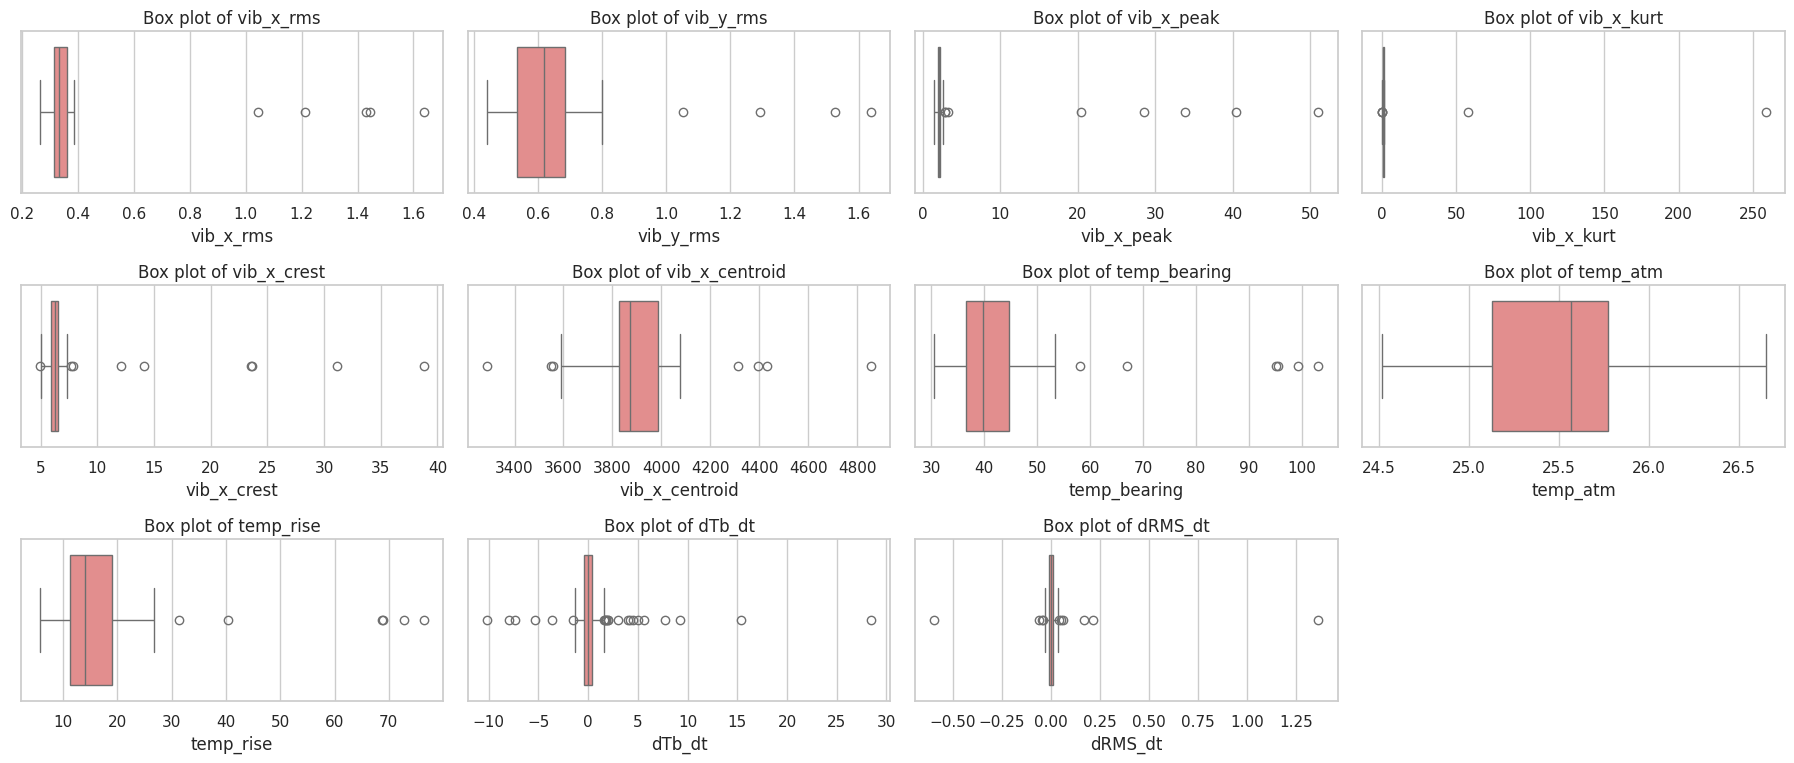

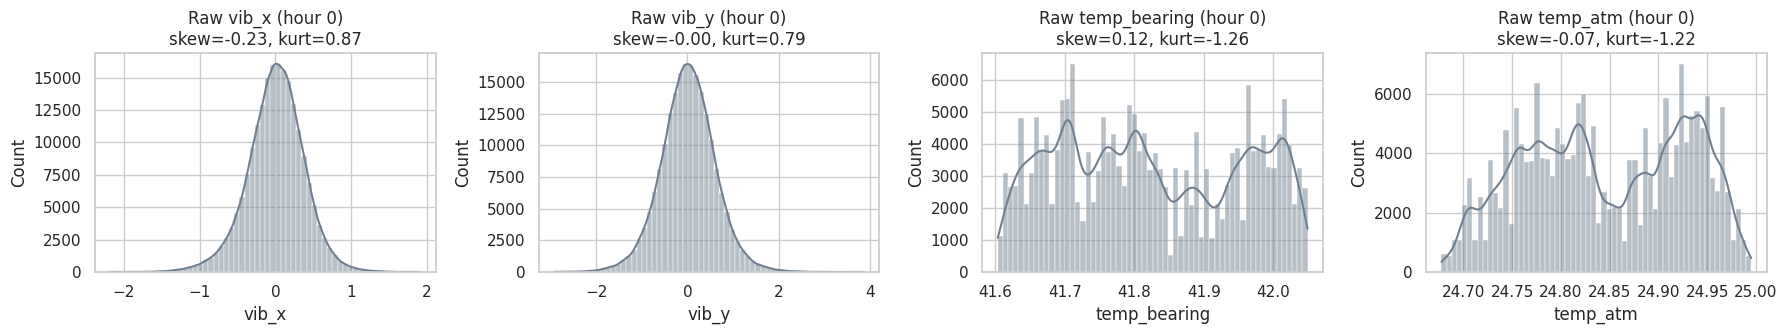

In [ ]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 2.6))
axes = axes.flatten()
for i, col in enumerate(key_num):
    sns.boxplot(x=df[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(f'Box plot of {col}')
for j in range(i + 1, len(axes)): axes[j].axis('off')
plt.tight_layout(); plt.show()

# Raw-signal distribution of the first hour (healthy bearing) – close to Gaussian if no defect
if df_raw is not None:
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
    sample = df_raw.sample(min(200_000, len(df_raw)), random_state=42)
    for ax, col in zip(axes, COLS):
        sns.histplot(sample[col], bins=60, kde=True, ax=ax, color='slategray')
        ax.set_title(f'Raw {col} (hour 0)\nskew={skew(sample[col]):.2f}, kurt={kurtosis(sample[col]):.2f}')
    plt.tight_layout(); plt.show()

#### 📝 Key findings – numerical distributions
* **Vibration indicators are extremely right-skewed** – RMS x: mean 0.371 vs. median 0.331 m/s², skewness 4.9, max 1.64; peak x: median 2.09 but max 51.0 m/s²; kurtosis x: median 1.08 but max 258.5. More than 120 of the 129 hours lie in a narrow band (RMS ≈ 0.26–0.40 m/s²); the long right tail consists only of the last few hours → **two regimes** (long normal operation + very short failure phase).
* **Kurtosis and crest factor** are above the Gaussian reference even in normal operation (median kurtosis 1.08 > 0; median crest 6.2) and explode only at failure (kurtosis 258 and crest 38.8 at the peak event) → impulsive impacts appear abruptly, not gradually.
* **Spectral centroid** is very stable (≈ 3.9 kHz, CV ≈ 4 %) → the frequency content changes little until the end.
* **Bearing temperature** (hourly mean) ranges 30.6–103.1 °C (median 39.8 °C); **ambient temperature** varies only 24.5–26.6 °C (CV 2 %). The **temperature rise** (bearing − ambient) ranges 5.8–76.5 °C.
* **Shapiro–Wilk p < 0.05 for every feature** (even ambient temperature, p = 0.003) → none is normally distributed → use **non-parametric** statistics (Spearman, Mann–Whitney, Kruskal–Wallis) and **robust scaling**.
* *Implications:* log-transform or clip energy features for linear models; the strong **imbalance** (very few failure-phase hours) must be handled when splitting and evaluating models.

### 3.3 Categorical variables
The KAIST files contain **no native categorical columns** (no team / provider). Two categorical variables are therefore **engineered**, because they are needed for stratified analysis and for the maintenance-trigger logic:

1. **`life_phase`** – quarter of the test life (Q1 … Q4) – a neutral time grouping.
2. **`health_stage`** – a condition-based label using **baseline 3-σ alarm limits** (baseline = hours 1 … 25.6, i.e. the first 20 % of life; hour 0 is excluded because it contains a start-up thermal transient – bearing temperature 41.8 °C in hour 0 vs. 31.7 °C in hour 1). An alarm is accepted only if it persists for **3 consecutive hours** (avoids false alarms) and, once raised, it is latched:
   * *Normal* – no sustained alarm,
   * *Thermal warning* – temperature rise (T_b − T_amb) above its baseline mean + 3σ,
   * *Vibration alarm* – vibration RMS x above its baseline mean + 3σ.

*Why two signals?* In the first version only vibration was used, and the data showed that vibration stays flat until ≈ hour 120 – a vibration-only stage label left the "degrading" class empty. Temperature changes much earlier (Section 5), so a two-signal staging reflects the actual degradation evidence.

In [ ]:
life = df['hour'].max()
df['life_phase'] = pd.cut(df['hour'], bins=4, labels=['Q1 (early)', 'Q2', 'Q3', 'Q4 (late)'], include_lowest=True)

# Baseline = first 20 % of life, excluding the start-up transient in the first record
base = df[(df['hour'] >= 1) & (df['hour'] <= 0.2 * life)]
ALARM      = base['vib_x_rms'].mean() + 3 * base['vib_x_rms'].std()     # vibration alarm limit
TEMP_ALARM = base['temp_rise'].mean() + 3 * base['temp_rise'].std()     # thermal alarm limit

def sustained_onset(series, limit, k=3):
    # First time step of the first run of k consecutive exceedances (None if never).
    run = (series > limit).astype(int).rolling(k).sum() >= k
    return int(df.loc[run, 'hour'].min() - (k - 1)) if run.any() else None

onset      = sustained_onset(df['vib_x_rms'], ALARM)         # vibration-alarm onset
temp_onset = sustained_onset(df['temp_rise'], TEMP_ALARM)    # thermal-warning onset

STAGE_COL = {'Normal': 'tab:green', 'Thermal warning': 'tab:orange', 'Vibration alarm': 'tab:red'}
df['health_stage'] = 'Normal'
if temp_onset is not None:
    df.loc[df['hour'] >= temp_onset, 'health_stage'] = 'Thermal warning'
if onset is not None:
    df.loc[df['hour'] >= onset, 'health_stage'] = 'Vibration alarm'
stage_order = [s_ for s_ in STAGE_COL if (df['health_stage'] == s_).any()]   # keep non-empty stages only
pal = [STAGE_COL[s_] for s_ in stage_order]
df['health_stage'] = pd.Categorical(df['health_stage'], categories=stage_order, ordered=True)

print(f'Vibration alarm limit (baseline mean + 3σ): RMS x = {ALARM:.4f} {VIB_UNIT}')
print(f'Thermal alarm limit  (baseline mean + 3σ): T_b − T_amb = {TEMP_ALARM:.2f} °C')
print(f'First single exceedance – vibration: {df.loc[df.vib_x_rms > ALARM, "hour"].min()}, '
      f'temperature rise: {df.loc[df.temp_rise > TEMP_ALARM, "hour"].min()}')
print(f'Sustained onset ({TIME_UNIT}) – thermal warning: {temp_onset}, vibration alarm: {onset} | end of life: {life}')
if onset is not None and temp_onset is not None:
    print(f'→ temperature gave {onset - temp_onset} {TIME_UNIT}s more warning than vibration; '
          f'vibration alarm came {life - onset} {TIME_UNIT}s before end of life')
for c in ['life_phase', 'health_stage']:
    print(f'\nFrequency counts – {c}'); print(df[c].value_counts(sort=False))
    print((df[c].value_counts(normalize=True, sort=False) * 100).round(1).astype(str) + ' %')

Vibration alarm limit (baseline mean + 3σ): RMS x = 0.3939 m/s²
Thermal alarm limit  (baseline mean + 3σ): T_b − T_amb = 13.57 °C
First single exceedance – vibration: 124, temperature rise: 0
Sustained onset (hour) – thermal warning: 48, vibration alarm: 124 | end of life: 128
→ temperature gave 76 hours more warning than vibration; vibration alarm came 4 hours before end of life

Frequency counts – life_phase
life_phase
Q1 (early)    33
Q2            32
Q3            32
Q4 (late)     32
Name: count, dtype: int64
life_phase
Q1 (early)    25.6 %
Q2            24.8 %
Q3            24.8 %
Q4 (late)     24.8 %
Name: proportion, dtype: object

Frequency counts – health_stage
health_stage
Normal             48
Thermal warning    76
Vibration alarm     5
Name: count, dtype: int64
health_stage
Normal             37.2 %
Thermal warning    58.9 %
Vibration alarm     3.9 %
Name: proportion, dtype: object


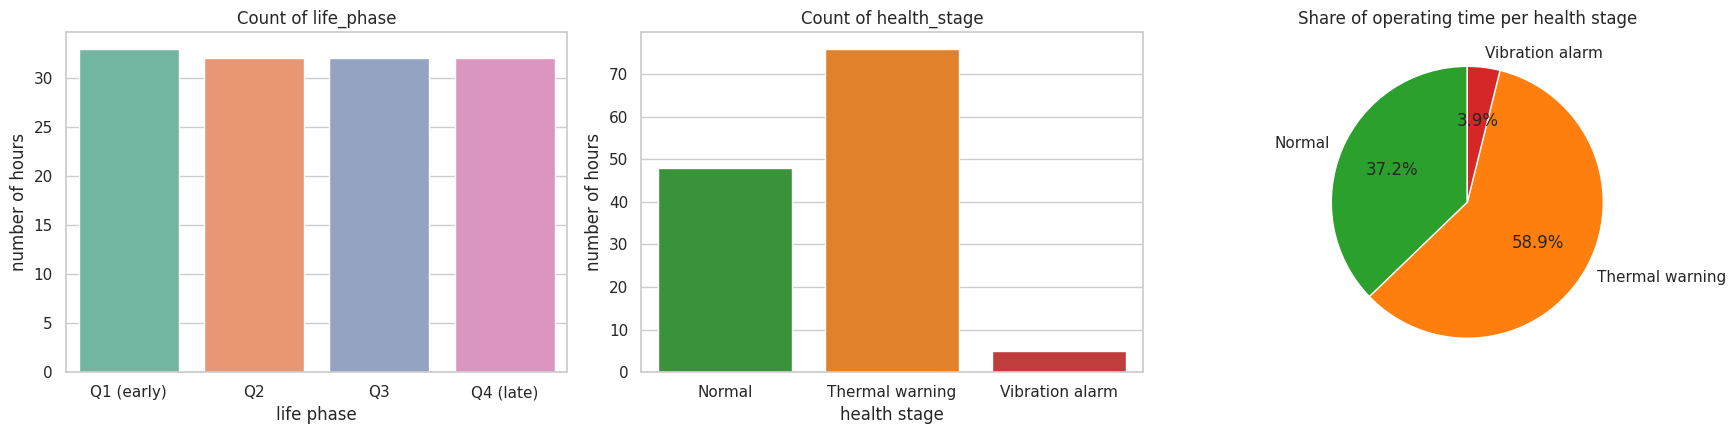

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=df, x='life_phase', ax=axes[0], palette='Set2')
axes[0].set_title('Count of life_phase'); axes[0].set_xlabel('life phase'); axes[0].set_ylabel(f'number of {TIME_UNIT}s')
sns.countplot(data=df, x='health_stage', order=stage_order, ax=axes[1], palette=pal)
axes[1].set_title('Count of health_stage'); axes[1].set_xlabel('health stage'); axes[1].set_ylabel(f'number of {TIME_UNIT}s')
vc = df['health_stage'].value_counts().reindex(stage_order)
axes[2].pie(vc, labels=vc.index, autopct='%1.1f%%', colors=pal, startangle=90)
axes[2].set_title('Share of operating time per health stage')
plt.tight_layout(); plt.show()

#### 📝 Key findings – categorical variables
* `life_phase` is balanced by construction (33 / 32 / 32 / 32 hours).
* **Alarm limits from the baseline (hours 1–25):** vibration RMS x > **0.394 m/s²**; temperature rise > **13.57 °C**. (Hour 0 also exceeds the thermal limit – 17.0 °C – but this is the start-up transient and is not sustained.)
* **Sustained onsets:** thermal warning at **hour 48**, vibration alarm at **hour 124** → temperature gave **76 hours** more warning than vibration; the vibration alarm came only **4 hours before end of life** (hour 128).
* **Stage counts:** Normal **48 h (37.2 %)**, Thermal warning **76 h (58.9 %)**, Vibration alarm **5 h (3.9 %)** → strong imbalance; the vibration-alarm class has only 5 samples.
* Stage means: RMS x 0.363 → 0.312 → 1.353 m/s²; bearing temperature 35.8 → 43.6 → 92.0 °C. Note that RMS is *lower* in the thermal-warning stage than in the normal stage.
* *Implications:* (i) a vibration-only PM trigger would leave ≈ 4 h for maintenance – too short for most planning horizons $H$ in Eq. (4); temperature-rise features are essential for an earlier trigger. (ii) Stratify/weight samples and report model errors per stage.

## 4. Multivariate Analysis
### 4.1 Correlation matrix (`df.corr()`) and heatmap
Both **Pearson** (linear) and **Spearman** (monotonic, rank-based, robust to the skewness found in Section 3) matrices are shown.

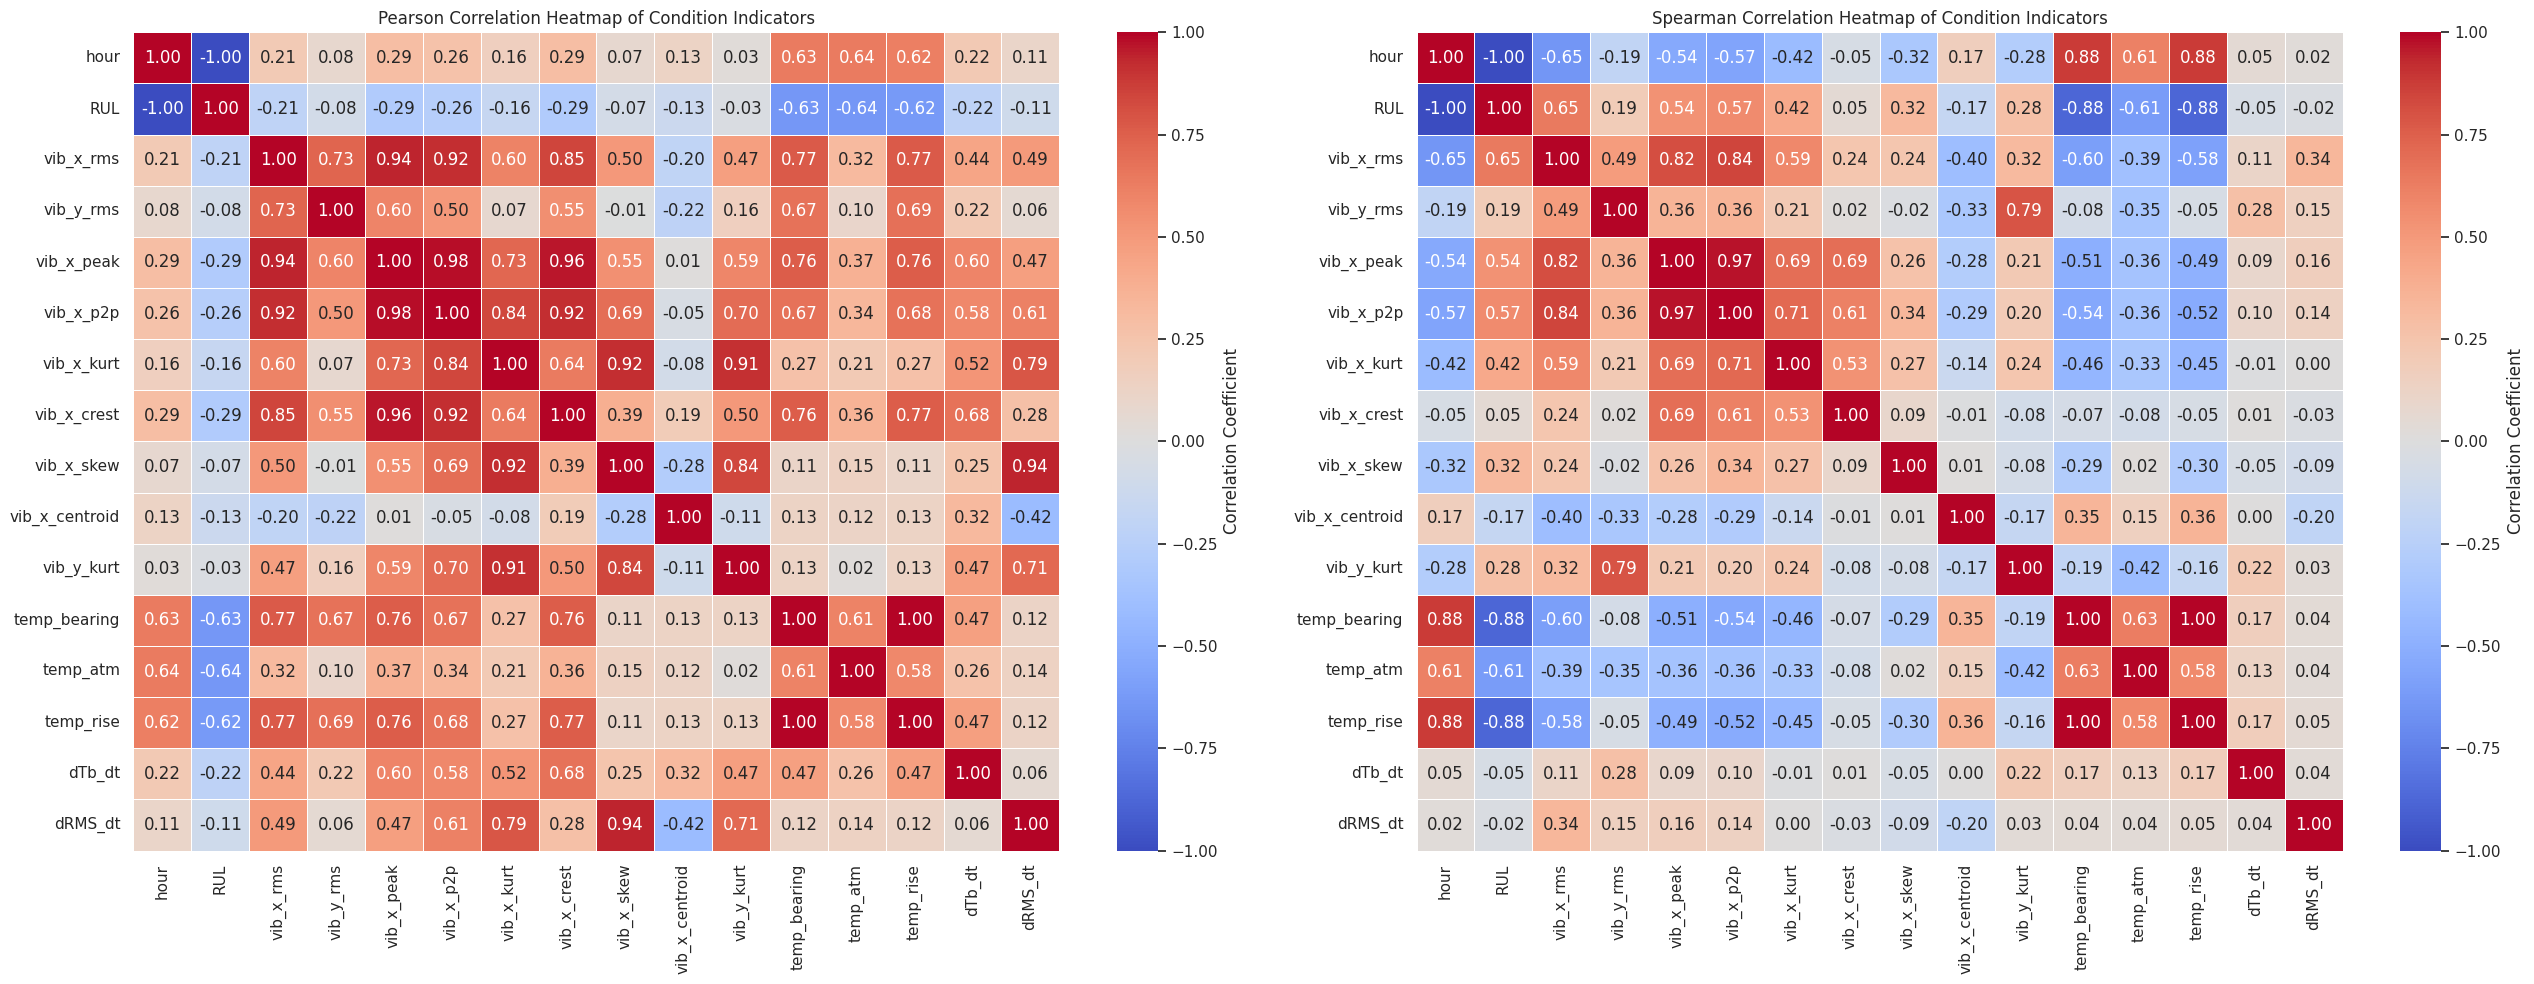

In [ ]:
corr_cols = ['hour', 'RUL', 'vib_x_rms', 'vib_y_rms', 'vib_x_peak', 'vib_x_p2p', 'vib_x_kurt',
             'vib_x_crest', 'vib_x_skew', 'vib_x_centroid', 'vib_y_kurt', 'temp_bearing', 'temp_atm',
             'temp_rise', 'dTb_dt', 'dRMS_dt']
fig, axes = plt.subplots(1, 2, figsize=(26, 10))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(df[corr_cols].corr(method=method), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                linewidths=0.5, ax=ax, cbar_kws={'label': 'Correlation Coefficient'})
    ax.set_title(f'{method.capitalize()} Correlation Heatmap of Condition Indicators')
plt.tight_layout(); plt.show()

### 4.2 Statistical significance of correlations (`scipy.stats.pearsonr` / `spearmanr`)
Each feature is tested against **RUL** (the target). H₀: no correlation. Significance level α = 0.05.

In [ ]:
rows = []
for c in [x for x in corr_cols if x not in ('hour', 'RUL')]:
    r_p, p_p = pearsonr(df[c], df['RUL'])
    r_s, p_s = spearmanr(df[c], df['RUL'])
    rows.append({'feature': c, 'Pearson r': r_p, 'Pearson p': p_p, 'Spearman ρ': r_s, 'Spearman p': p_s,
                 'significant (α=0.05)': 'yes' if min(p_p, p_s) < 0.05 else 'no'})
sig_tbl = pd.DataFrame(rows).set_index('feature').sort_values('Spearman ρ', key=np.abs, ascending=False)
display(sig_tbl.style.format({'Pearson r': '{:.3f}', 'Spearman ρ': '{:.3f}', 'Pearson p': '{:.2e}', 'Spearman p': '{:.2e}'}))

# Redundancy check: highly inter-correlated feature pairs (|ρ| > 0.9) – candidates for removal
sp = df[corr_cols].drop(columns=['hour', 'RUL']).corr('spearman').abs()
pairs = sp.where(np.triu(np.ones(sp.shape), 1).astype(bool)).stack()
print('\nRedundant pairs (|Spearman| > 0.9):'); print(pairs[pairs > 0.9].sort_values(ascending=False).round(3))

,Pearson r,Pearson p,Spearman ρ,Spearman p,significant (α=0.05)
feature,,,,,
temp_bearing,-0.634,7.31e-16,-0.881,3.69e-43,yes
temp_rise,-0.622,3.63e-15,-0.875,6.29e-42,yes
vib_x_rms,-0.209,1.77e-02,0.648,9.73e-17,yes
temp_atm,-0.638,4.25e-16,-0.613,1.19e-14,yes
vib_x_p2p,-0.261,2.79e-03,0.568,2.30e-12,yes
vib_x_peak,-0.291,8.22e-04,0.538,5.02e-11,yes
vib_x_kurt,-0.163,6.48e-02,0.416,9.15e-07,yes
vib_x_skew,-0.071,4.23e-01,0.321,2.06e-04,yes
vib_y_kurt,-0.025,7.75e-01,0.277,1.47e-03,yes



Redundant pairs (|Spearman| > 0.9):
temp_bearing  temp_rise   0.9950
vib_x_peak    vib_x_p2p   0.9750
dtype: float64


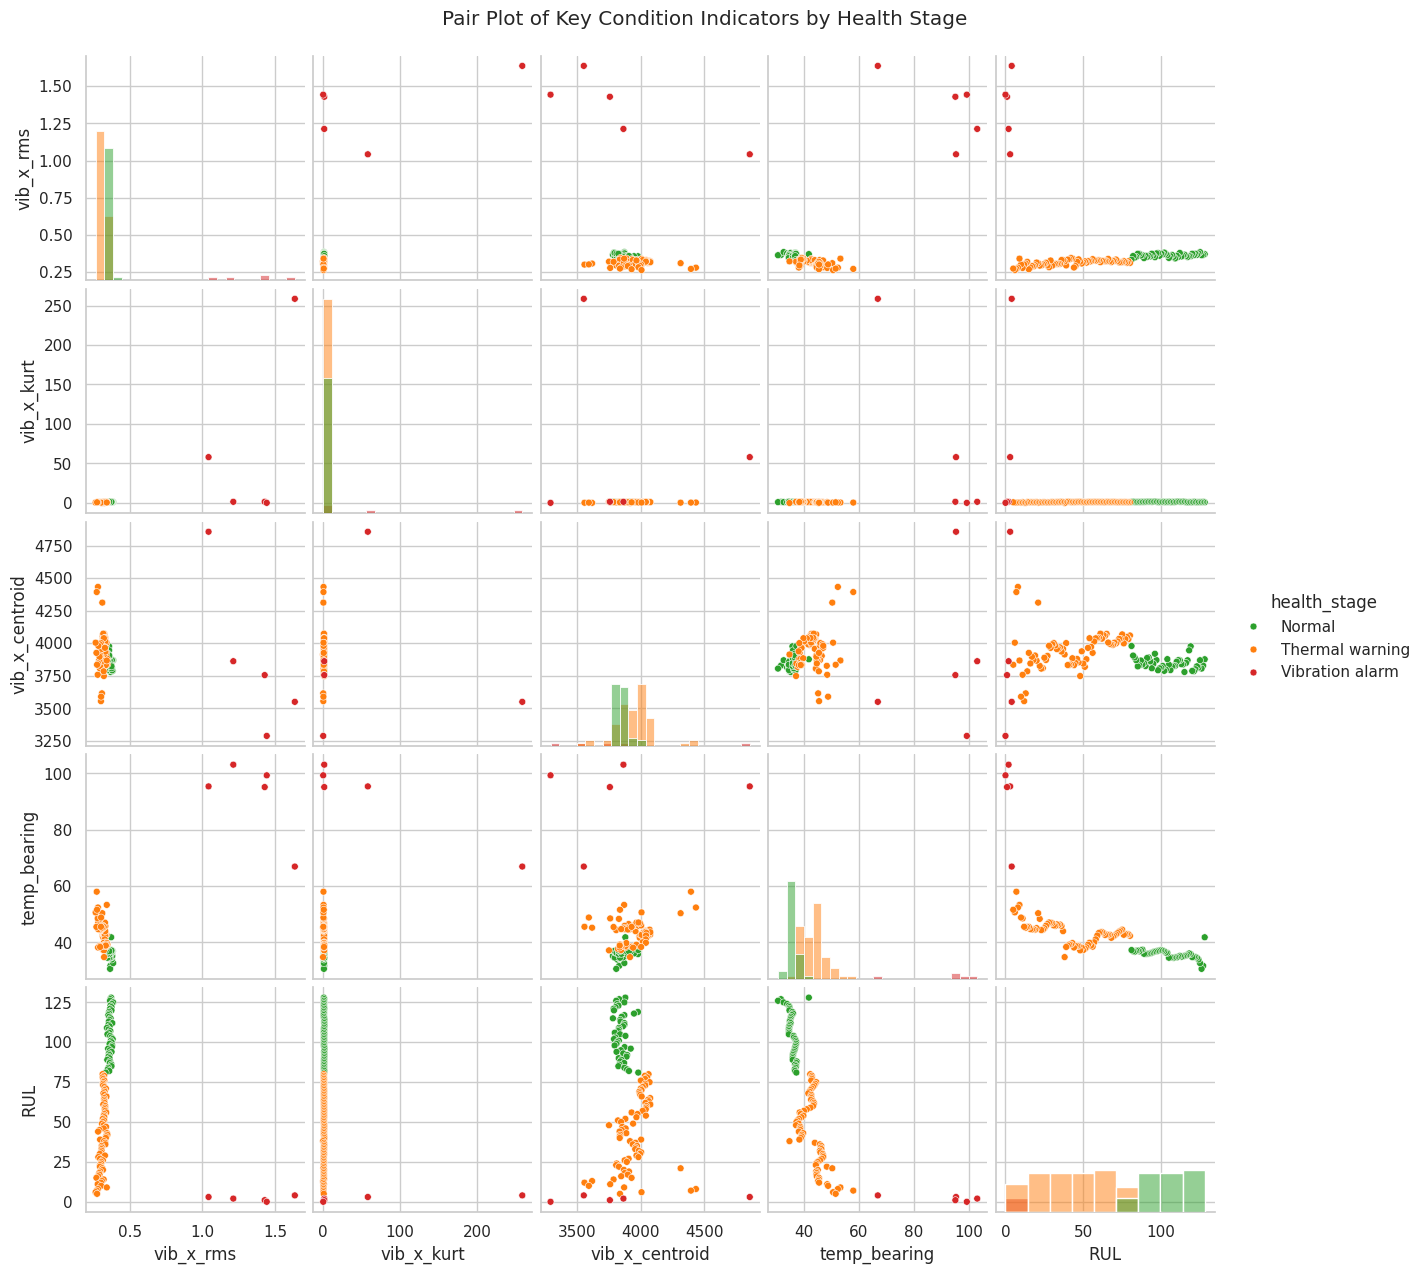

In [ ]:
# Pair plot of the most informative indicators coloured by health stage
pp_cols = ['vib_x_rms', 'vib_x_kurt', 'vib_x_centroid', 'temp_bearing', 'RUL']
g = sns.pairplot(df[pp_cols + ['health_stage']].astype({'health_stage': str}), hue='health_stage',
                 hue_order=stage_order, palette=pal, diag_kind='hist', plot_kws={'s': 25})
g.fig.suptitle('Pair Plot of Key Condition Indicators by Health Stage', y=1.02); plt.show()

#### 📝 Key findings – correlations
* **Temperature is the strongest correlate of RUL:** Spearman ρ = −0.881 (bearing temperature) and −0.875 (temperature rise), p < 1e-40 → temperature increases steadily as life is consumed.
* **Vibration shows a sign reversal between Pearson and Spearman:** RMS x has Pearson r = −0.209 (p = 0.018) but Spearman ρ = **+0.648** (p ≈ 1e-16). The rank correlation is *positive* because RMS **slowly decreases** during most of the life (≈ 0.37 → 0.30 m/s²), while the Pearson value is pulled negative by the **few extreme failure hours**. The same pattern holds for peak (ρ = +0.54), p2p (+0.57) and kurtosis (+0.42). This is a key insight: **over 95 % of the life, higher vibration does *not* mean shorter remaining life**.
* **Ambient temperature** also correlates with RUL (ρ = −0.61) – it drifted upward during the test (≈ 24.5 → 26.6 °C). This is a **time confound** (seasonal/room drift), not a cause of failure.
* **Not useful (not significant, |ρ| < 0.2):** spectral centroid x (ρ = −0.17, p = 0.06), crest factor x (ρ = 0.05), and the hourly slope features `dTb_dt`, `dRMS_dt` (|ρ| < 0.1) – the hourly slopes are too noisy without smoothing.
* **Redundancy:** temp_bearing ↔ temp_rise (|ρ| = 0.995) and peak ↔ p2p (0.975) → keep one of each pair (temp_rise, because it removes ambient noise; peak or p2p). RMS ≈ std (DC offset ≈ 0).
* *Implications for feature selection:* temperature rise + RMS + kurtosis (+ peak) are the most informative; slopes must be computed on **smoothed** series (e.g. rolling mean) before use; linear correlation (Pearson) alone is misleading here.

### 4.3 Numerical vs. categorical relationships (box plots and violin plots)

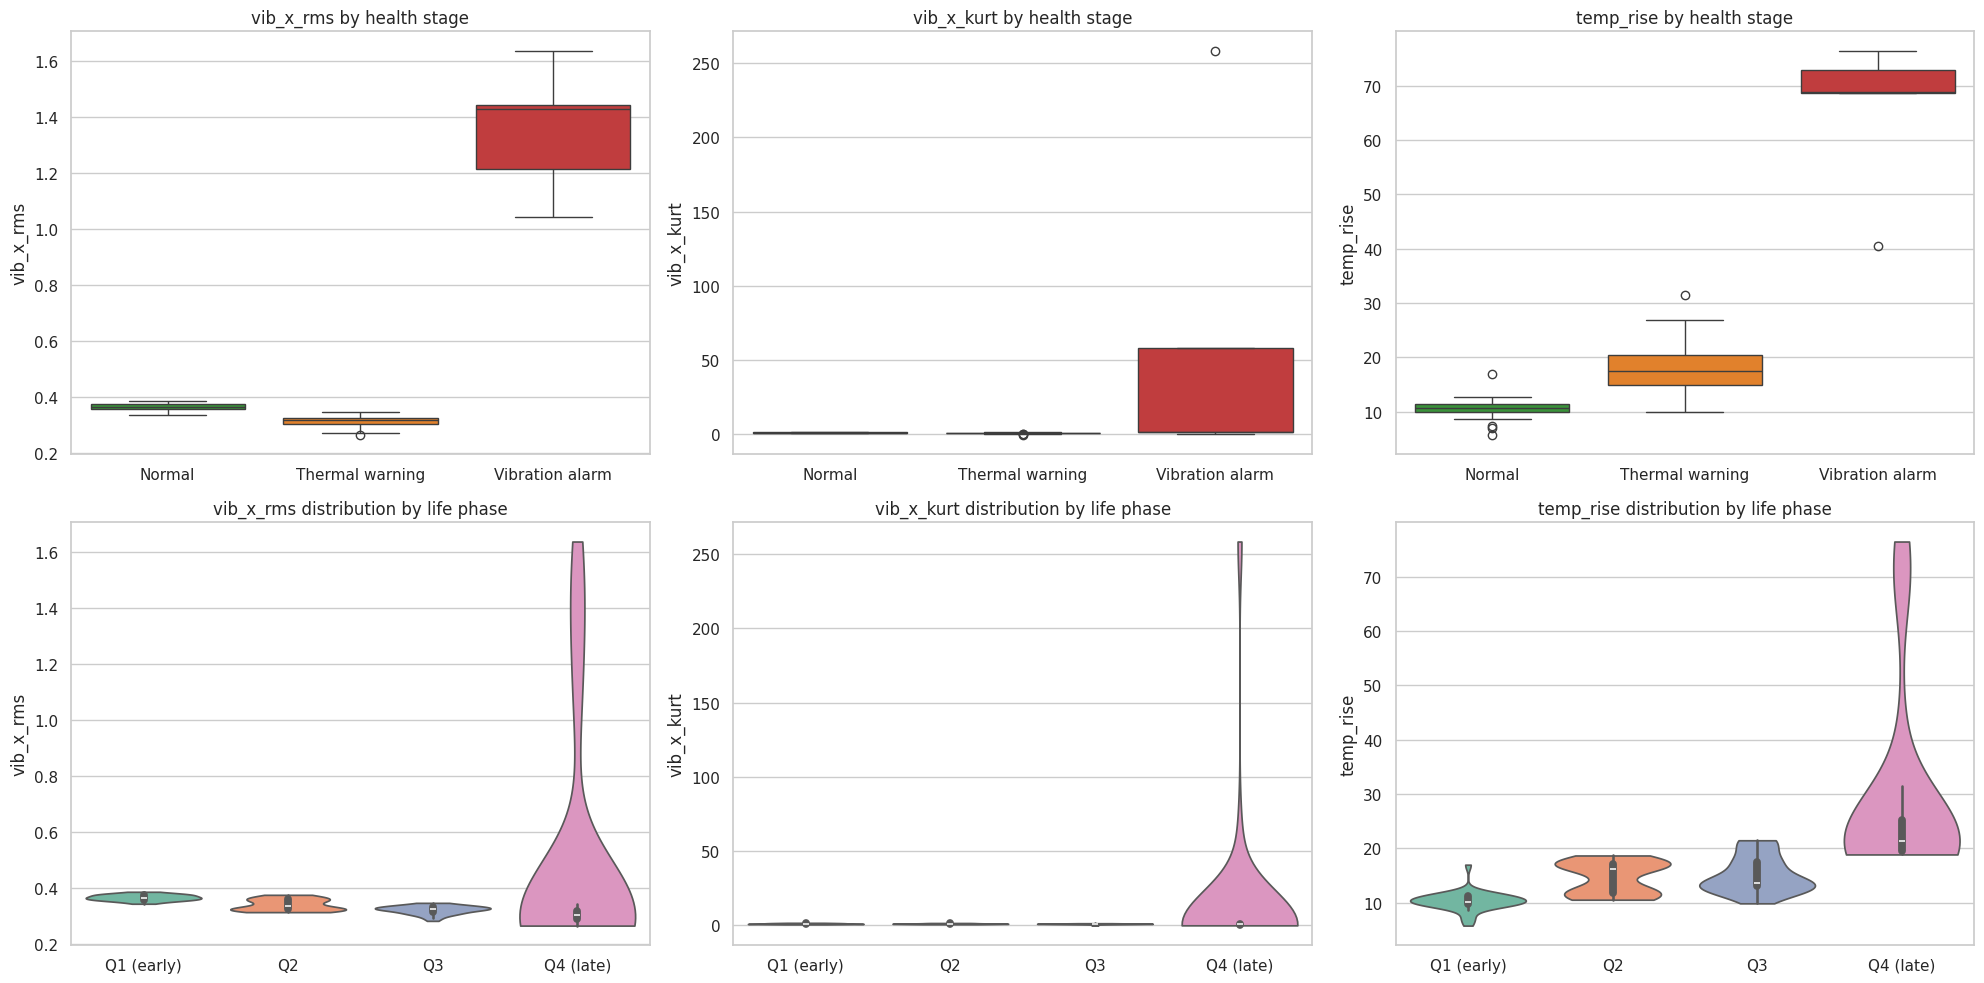

Mann-Whitney U (vib_x_rms, Q1 vs Q4): U=891.0, p=1.969e-06, median Q1=0.364, median Q4=0.301, ratio Q4/Q1=0.83
Mann-Whitney U (temp_rise, Q1 vs Q4): U=0.0, p=4.464e-12, median Q1=10.17 °C, median Q4=21.29 °C
Kruskal-Wallis (temp_rise across life phases): H=94.3, p=2.56e-20


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for k, col in enumerate(['vib_x_rms', 'vib_x_kurt', 'temp_rise']):
    sns.boxplot(data=df, x='health_stage', y=col, order=stage_order, palette=pal, ax=axes[0, k])
    axes[0, k].set_title(f'{col} by health stage'); axes[0, k].set_xlabel('')
    sns.violinplot(data=df, x='life_phase', y=col, palette='Set2', ax=axes[1, k], cut=0)
    axes[1, k].set_title(f'{col} distribution by life phase'); axes[1, k].set_xlabel('')
plt.tight_layout(); plt.show()

# Non-parametric test: does vibration in the last quarter differ from the first quarter? (Mann-Whitney U, L3)
a = df.loc[df['life_phase'] == 'Q1 (early)', 'vib_x_rms']; b = df.loc[df['life_phase'] == 'Q4 (late)', 'vib_x_rms']
u, p = mannwhitneyu(a, b, alternative='two-sided')
print(f'Mann-Whitney U (vib_x_rms, Q1 vs Q4): U={u:.1f}, p={p:.3e}, median Q1={a.median():.3f}, '
      f'median Q4={b.median():.3f}, ratio Q4/Q1={b.median()/a.median():.2f}')
a2 = df.loc[df['life_phase'] == 'Q1 (early)', 'temp_rise']; b2 = df.loc[df['life_phase'] == 'Q4 (late)', 'temp_rise']
u2, p2 = mannwhitneyu(a2, b2, alternative='two-sided')
print(f'Mann-Whitney U (temp_rise, Q1 vs Q4): U={u2:.1f}, p={p2:.3e}, median Q1={a2.median():.2f} °C, median Q4={b2.median():.2f} °C')
# Kruskal-Wallis: does the temperature rise differ between the four life phases?
h_kw, p_kw = stats.kruskal(*[g_['temp_rise'].values for _, g_ in df.groupby('life_phase', observed=True)])
print(f'Kruskal-Wallis (temp_rise across life phases): H={h_kw:.1f}, p={p_kw:.2e}')

#### 📝 Key findings – numerical vs. categorical
* **Vibration does not separate the life phases in the expected direction.** Mann–Whitney (RMS x, Q1 vs. Q4): U = 891, p = 2.0e-6, but the **median RMS of Q4 (0.301) is 17 % *lower* than Q1 (0.364)**. The Q4 *mean* (0.46 m/s²) is higher only because of the last ≈ 5 hours (very tall, thin Q4 violin). By stage, RMS is even lower in *Thermal warning* (0.31) than in *Normal* (0.36), and only the *Vibration alarm* stage is clearly higher (≈ 1.0–1.6 m/s²).
* **Temperature rise separates both stages and phases clearly:** Mann–Whitney Q1 vs. Q4: U = 0, p = 4.5e-12 (median 10.2 → 21.3 °C – every Q4 hour is warmer than every Q1 hour); Kruskal–Wallis across the four phases: H = 94.3, p = 2.6e-20. The stage box plots show almost no overlap (Normal ≈ 10–12 °C, Thermal warning ≈ 15–20 °C, Vibration alarm ≈ 69–77 °C).
* **Kurtosis** is ≈ 1 in all phases and stages except two failure hours (258 at hour 124 and 58), then falls back to ≈ 2 at hours 127–128 → kurtosis detects the **moment of impact/damage initiation**, but it is **non-monotonic** → a good **detection** feature, a poor **RUL** feature.
* *Implications:* use temperature-rise features for **prognosis** (long horizon) and kurtosis/peak/RMS for **detection/confirmation** of the final failure phase.

### 4.4 Simple linear regression with `statsmodels`
Two OLS models are fitted:
* **Model A:** `RUL ~ vib_x_rms` – how much RUL decreases per unit vibration (baseline for the later RUL model).
* **Model B:** `temp_bearing ~ vib_x_rms + temp_atm` – separates the effect of degradation (vibration) from the **ambient-temperature noise factor** on bearing temperature (P-diagram check).
* **Model B2:** Model B + `hour` – controls for the common time trend (both ambient and bearing temperature drift upward during the test), to check whether the ambient effect is real or a time confound.

In [ ]:
model_a = smf.ols('RUL ~ vib_x_rms', data=df).fit()
print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:                    RUL   R-squared:                       0.044
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     5.776
Date:                Thu, 05 Nov 2026   Prob (F-statistic):             0.0177
Time:                        19:46:30   Log-Likelihood:                -646.81
No. Observations:                 129   AIC:                             1298.
Df Residuals:                     127   BIC:                             1303.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     78.1865      6.730     11.618      0.0

In [ ]:
model_b = smf.ols('temp_bearing ~ vib_x_rms + temp_atm', data=df).fit()
print(model_b.summary())
model_b2 = smf.ols('temp_bearing ~ vib_x_rms + temp_atm + hour', data=df).fit()
print(model_b2.summary().tables[1])

# Also test a log-transformed predictor (motivated by the right-skewed RMS distribution)
df['log_vib_x_rms'] = np.log(df['vib_x_rms'])
model_c = smf.ols('RUL ~ log_vib_x_rms', data=df).fit()
cmp = pd.DataFrame({'R²': [model_a.rsquared, model_c.rsquared], 'adj. R²': [model_a.rsquared_adj, model_c.rsquared_adj],
                    'AIC': [model_a.aic, model_c.aic]}, index=['RUL ~ rms', 'RUL ~ log(rms)'])
display(cmp)

                            OLS Regression Results                            
Dep. Variable:           temp_bearing   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.730
Method:                 Least Squares   F-statistic:                     174.4
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           5.03e-37
Time:                        19:46:30   Log-Likelihood:                -411.40
No. Observations:                 129   AIC:                             828.8
Df Residuals:                     126   BIC:                             837.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -201.5573     27.271     -7.391      0.0

,R²,adj. R²,AIC
RUL ~ rms,0.0435,0.0360,"1,297.6198"
RUL ~ log(rms),0.0043,-0.0036,"1,302.8075"


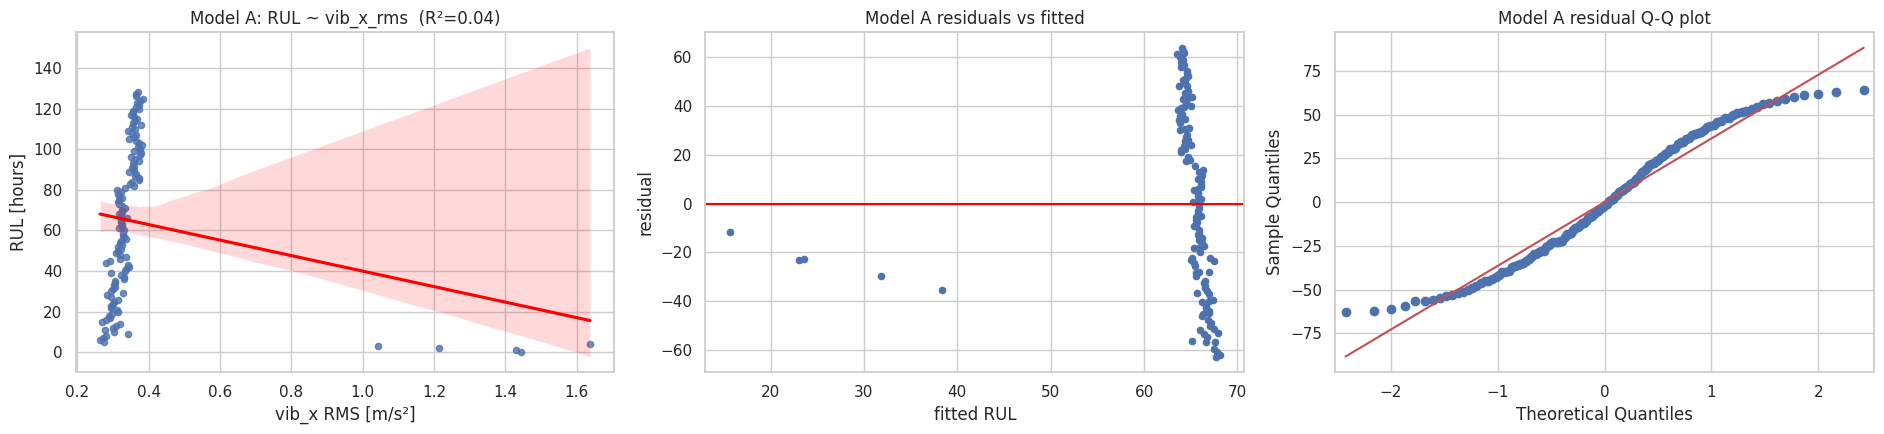

Auto-interpretation:
 • Model A: each +1 m/s² of RMS changes RUL by -38.2 hours (p=1.77e-02); R²=0.044.
 • Model B: vib coef=35.724 (p=1.97e-25); temp_atm coef=9.055 °C/°C (p=9.23e-14); R²=0.735.
 • Model B2 (+hour): temp_atm coef=3.243 (p=3.55e-03); hour coef=0.125 °C/h (p=2.25e-14); R²=0.834.
 • Durbin-Watson of residuals: A=0.020, B=0.990, B2=1.524  (≈2 = independent errors; ≪2 = strong positive autocorrelation)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
sns.regplot(data=df, x='vib_x_rms', y='RUL', ax=axes[0], scatter_kws={'s': 20}, line_kws={'color': 'red'})
axes[0].set_title(f'Model A: RUL ~ vib_x_rms  (R²={model_a.rsquared:.2f})'); axes[0].set_xlabel(f'vib_x RMS [{VIB_UNIT}]'); axes[0].set_ylabel(f'RUL [{TIME_UNIT}s]')
axes[1].scatter(model_a.fittedvalues, model_a.resid, s=20); axes[1].axhline(0, color='red')
axes[1].set_title('Model A residuals vs fitted'); axes[1].set_xlabel('fitted RUL'); axes[1].set_ylabel('residual')
sm.qqplot(model_a.resid, line='s', ax=axes[2]); axes[2].set_title('Model A residual Q-Q plot')
plt.tight_layout(); plt.show()

print('Auto-interpretation:')
b1, p1 = model_a.params['vib_x_rms'], model_a.pvalues['vib_x_rms']
print(f" • Model A: each +1 {VIB_UNIT} of RMS changes RUL by {b1:.1f} {TIME_UNIT}s (p={p1:.2e}); R²={model_a.rsquared:.3f}.")
print(f" • Model B: vib coef={model_b.params['vib_x_rms']:.3f} (p={model_b.pvalues['vib_x_rms']:.2e}); "
      f"temp_atm coef={model_b.params['temp_atm']:.3f} °C/°C (p={model_b.pvalues['temp_atm']:.2e}); R²={model_b.rsquared:.3f}.")
print(f" • Model B2 (+hour): temp_atm coef={model_b2.params['temp_atm']:.3f} (p={model_b2.pvalues['temp_atm']:.2e}); "
      f"hour coef={model_b2.params['hour']:.3f} °C/h (p={model_b2.pvalues['hour']:.2e}); R²={model_b2.rsquared:.3f}.")
from statsmodels.stats.stattools import durbin_watson
print(f" • Durbin-Watson of residuals: A={durbin_watson(model_a.resid):.3f}, B={durbin_watson(model_b.resid):.3f}, "
      f"B2={durbin_watson(model_b2.resid):.3f}  (≈2 = independent errors; ≪2 = strong positive autocorrelation)")

#### 📝 Key findings – regression
* **Model A (RUL ~ RMS x):** slope = −38.2 h per m/s² (p = 0.018) but **R² = 0.044** – vibration RMS explains only 4 % of the RUL variance. The negative slope is created by the 5 failure hours; for the other 124 hours RMS is almost constant (and slightly decreasing). log(RMS) is worse (R² = 0.004; AIC 1302.8 vs. 1297.6).
* **Residual diagnostics:** the residual plot shows a strong pattern (a vertical band – many RUL values for the same RMS) and **Durbin–Watson = 0.02** → residuals are almost perfectly autocorrelated, so the OLS **p-values are over-optimistic** (the 129 hours are not independent observations).
* **Model B (T_b ~ RMS + T_amb):** R² = 0.735; vibration coefficient **35.7 °C per m/s²** (p ≈ 2e-25) – high vibration and high bearing temperature occur together at failure. The ambient coefficient **9.05 °C per °C** (p ≈ 9e-14) is physically implausible.
* **Model B2 (+ hour) confirms the time confound:** adding operating time reduces the ambient coefficient from 9.05 to **3.24 °C per °C** (p = 0.004), time itself is strongly significant (**+0.125 °C per hour**, p ≈ 2e-14), R² rises to **0.834** and Durbin–Watson improves from 0.99 to 1.52. So most of the "ambient effect" in Model B was really the slow **degradation-related warming over time**; the remaining 3.2 °C/°C is still larger than physically expected (residual confounding / non-linear warming) → **ambient correction by subtraction (T_b − T_amb)** is the safer choice.
* *Implications for modeling:* (i) single-feature linear models are a very weak baseline here → supports the Assignment-2 choice of a **non-linear tree-based primary model (Random Forest / gradient boosting)** with linear regression as the baseline; (ii) use the **temperature rise** and an explicit time/trend feature; (iii) use a **time-ordered train/test split** – samples are autocorrelated.

## 5. Time-Series Summarization and Trend Analysis
In this dataset the **operating hour** is the time axis and **RUL / lifetime** is the time-to-event proxy (the instructions' "lifetime" column). Groups are formed over **intervals** (8-hour shifts and life phases), equivalent to the *mean lifetime per team/provider* summary in the instructions.

In [ ]:
df['shift_block'] = (df['hour'] // 8).astype(int)            # 8-hour operating blocks (like work shifts)

block = df.groupby('shift_block').agg(start=('hour', 'min'), mean_RUL=('RUL', 'mean'),
                                       rms_x_mean=('vib_x_rms', 'mean'), rms_x_max=('vib_x_rms', 'max'),
                                       kurt_x_mean=('vib_x_kurt', 'mean'), temp_b_mean=('temp_bearing', 'mean'),
                                       temp_rise_mean=('temp_rise', 'mean'), alarms=('any_outlier_z', 'sum'))
block['rms_growth_%'] = block['rms_x_mean'].pct_change() * 100
display(block)

phase = df.groupby('life_phase', observed=True)[['RUL', 'vib_x_rms', 'vib_x_kurt', 'temp_bearing', 'temp_rise']].agg(['mean', 'std'])
display(phase)
stage = df.groupby('health_stage', observed=True).agg(n=('hour', 'size'), mean_RUL=('RUL', 'mean'),
                                                      rms=('vib_x_rms', 'mean'), temp=('temp_bearing', 'mean'))
display(stage)

,start,mean_RUL,rms_x_mean,rms_x_max,kurt_x_mean,temp_b_mean,temp_rise_mean,alarms,rms_growth_%
shift_block,,,,,,,,,
0,0,124.5000,0.3708,0.3850,1.0640,34.3623,9.2875,1,NaN
1,8,116.5000,0.3602,0.3738,1.1196,35.3611,10.2116,0,-2.8537
2,16,108.5000,0.3572,0.3792,1.3745,34.7299,10.0471,0,-0.8371
3,24,100.5000,0.3724,0.3817,1.2284,36.8622,11.3981,0,4.2389
4,32,92.5000,0.3575,0.3741,1.5471,36.2047,10.8121,0,-3.9766
5,40,84.5000,0.3581,0.3737,1.2682,37.0572,12.2202,0,0.1632
6,48,76.5000,0.3173,0.3242,0.9175,43.2816,17.5600,0,-11.3865
7,56,68.5000,0.3269,0.3390,1.1002,42.5566,16.8729,0,3.0116
8,64,60.5000,0.3260,0.3312,1.1089,42.5222,16.8935,0,-0.2657


RUL        vib_x_rms        vib_x_kurt         temp_bearing  \
               mean    std      mean    std       mean     std         mean   
life_phase                                                                    
Q1 (early) 112.0000 9.6695    0.3647 0.0107     1.2142  0.2941      35.3715   
Q2          79.5000 9.3808    0.3391 0.0205     1.1843  0.2519      39.9599   
Q3          47.5000 9.3808    0.3206 0.0149     1.0823  0.2835      40.6821   
Q4 (late)   15.5000 9.3808    0.4615 0.3989    10.5494 46.3696      54.3916   

                   temp_rise          
               std      mean     std  
life_phase                            
Q1 (early)  1.8901   10.2677  1.7982  
Q2          3.2450   14.5389  2.9599  
Q3          3.1965   15.2065  3.3683  
Q4 (late)  17.4979   28.4062 17.2291

,n,mean_RUL,rms,temp
health_stage,,,,
Normal,48,104.5000,0.3627,35.7629
Thermal warning,76,42.5000,0.3123,43.5767
Vibration alarm,5,2.0000,1.3534,91.9765


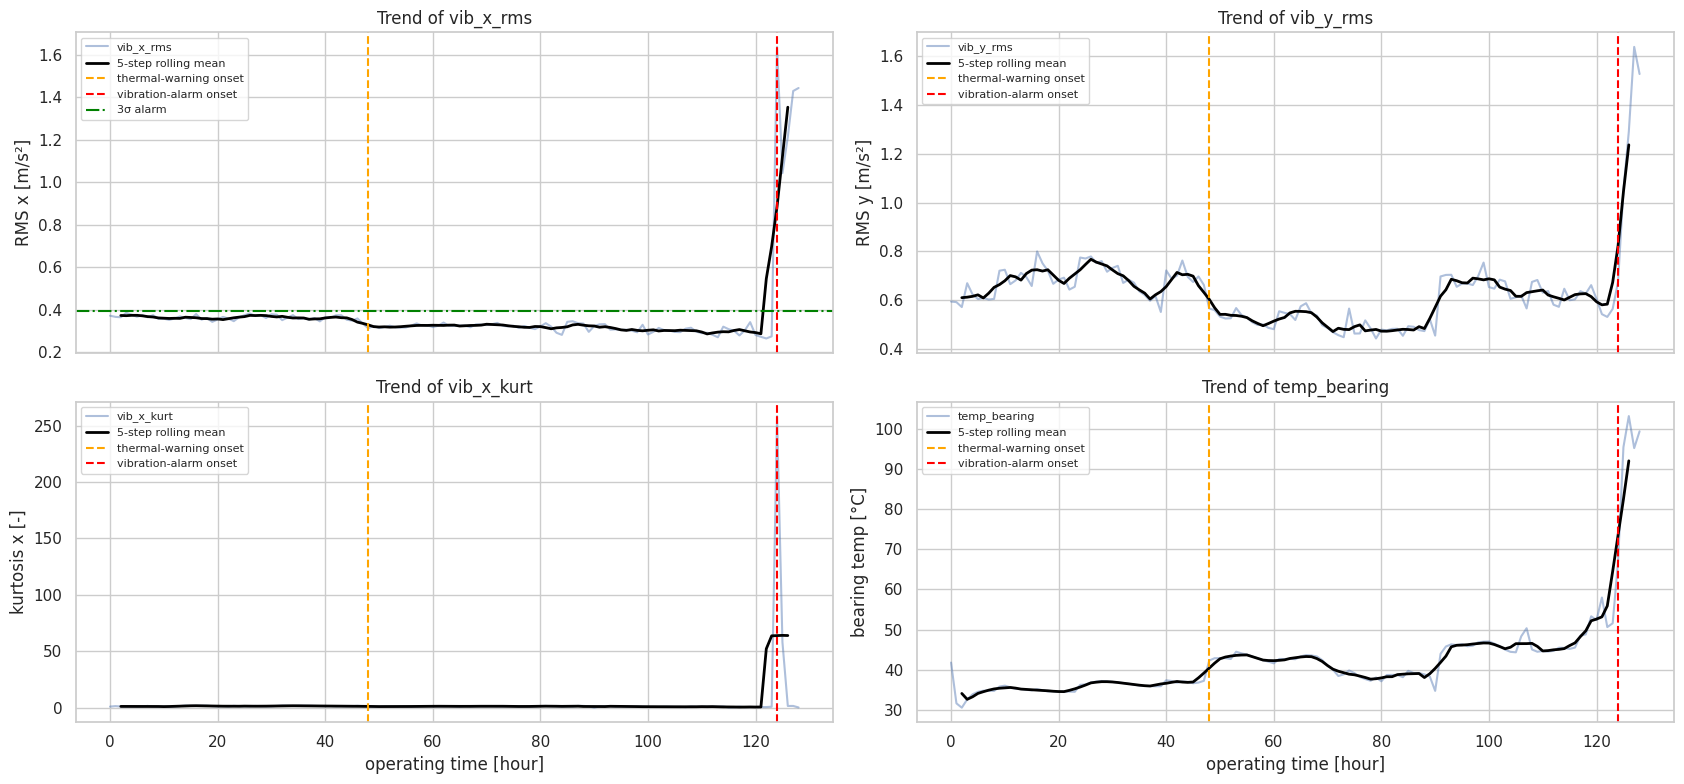

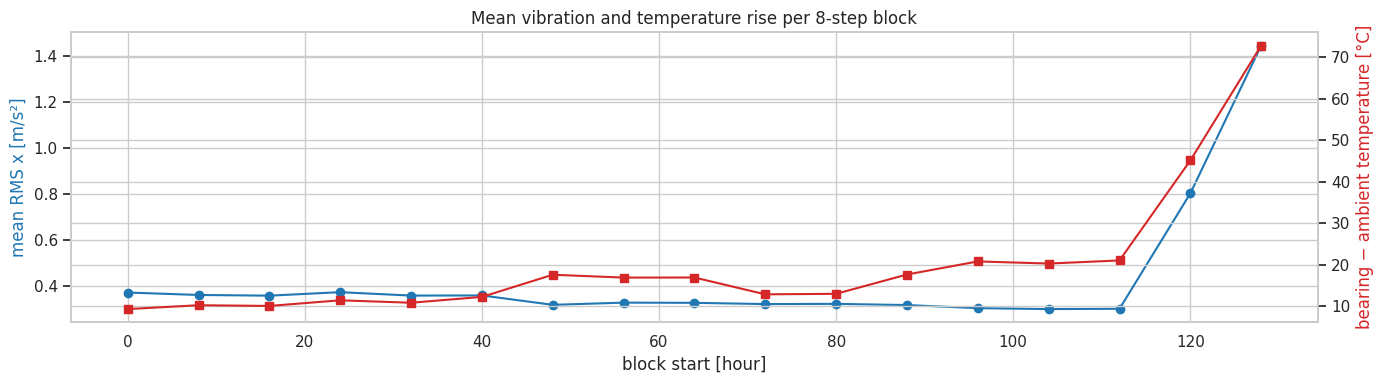

In [ ]:
# Trend line plots with rolling mean (course: TimeSeries_Analysis.ipynb)
ROLL = 5
fig, axes = plt.subplots(2, 2, figsize=(17, 8), sharex=True)
for ax, (col, lab) in zip(axes.flatten(), [('vib_x_rms', f'RMS x [{VIB_UNIT}]'), ('vib_y_rms', f'RMS y [{VIB_UNIT}]'),
                                            ('vib_x_kurt', 'kurtosis x [-]'), ('temp_bearing', 'bearing temp [°C]')]):
    ax.plot(df['hour'], df[col], alpha=0.45, label=col)
    ax.plot(df['hour'], df[col].rolling(ROLL, center=True).mean(), color='black', lw=2, label=f'{ROLL}-step rolling mean')
    if temp_onset is not None: ax.axvline(temp_onset, color='orange', ls='--', label='thermal-warning onset')
    if onset is not None: ax.axvline(onset, color='red', ls='--', label='vibration-alarm onset')
    ax.set_ylabel(lab); ax.set_title(f'Trend of {col}'); ax.legend(fontsize=8)
axes[0, 0].axhline(ALARM, color='green', ls='-.', label='3σ alarm'); axes[0, 0].legend(fontsize=8)
for ax in axes[1]: ax.set_xlabel(f'operating time [{TIME_UNIT}]')
plt.tight_layout(); plt.show()

# Block-level trend (mean per 8-h block)
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(block['start'], block['rms_x_mean'], marker='o', color='tab:blue', label='mean RMS x')
ax1.set_xlabel(f'block start [{TIME_UNIT}]'); ax1.set_ylabel(f'mean RMS x [{VIB_UNIT}]', color='tab:blue')
ax2 = ax1.twinx(); ax2.plot(block['start'], block['temp_rise_mean'], marker='s', color='tab:red', label='mean temp rise')
ax2.set_ylabel('bearing − ambient temperature [°C]', color='tab:red')
ax1.set_title('Mean vibration and temperature rise per 8-step block'); fig.tight_layout(); plt.show()

### 5.1 Trend / seasonality decomposition (`statsmodels.tsa.seasonal_decompose`) and stationarity test
A **24-step period** is tested because the ambient temperature can follow a **daily cycle** (the test ran > 5 days, 20 June 17:00 → 26 June). Note: `seasonal_decompose` *always* returns a seasonal component, even for pure noise, so its size is not proof of seasonality. The daily cycle is therefore also **tested statistically**: the series is detrended (24-h centred rolling mean) and the residuals are compared across the 24 clock hours with the non-parametric **Kruskal–Wallis test** (H₀: no difference between clock hours). The vibration-alarm hours are excluded so the failure does not dominate.

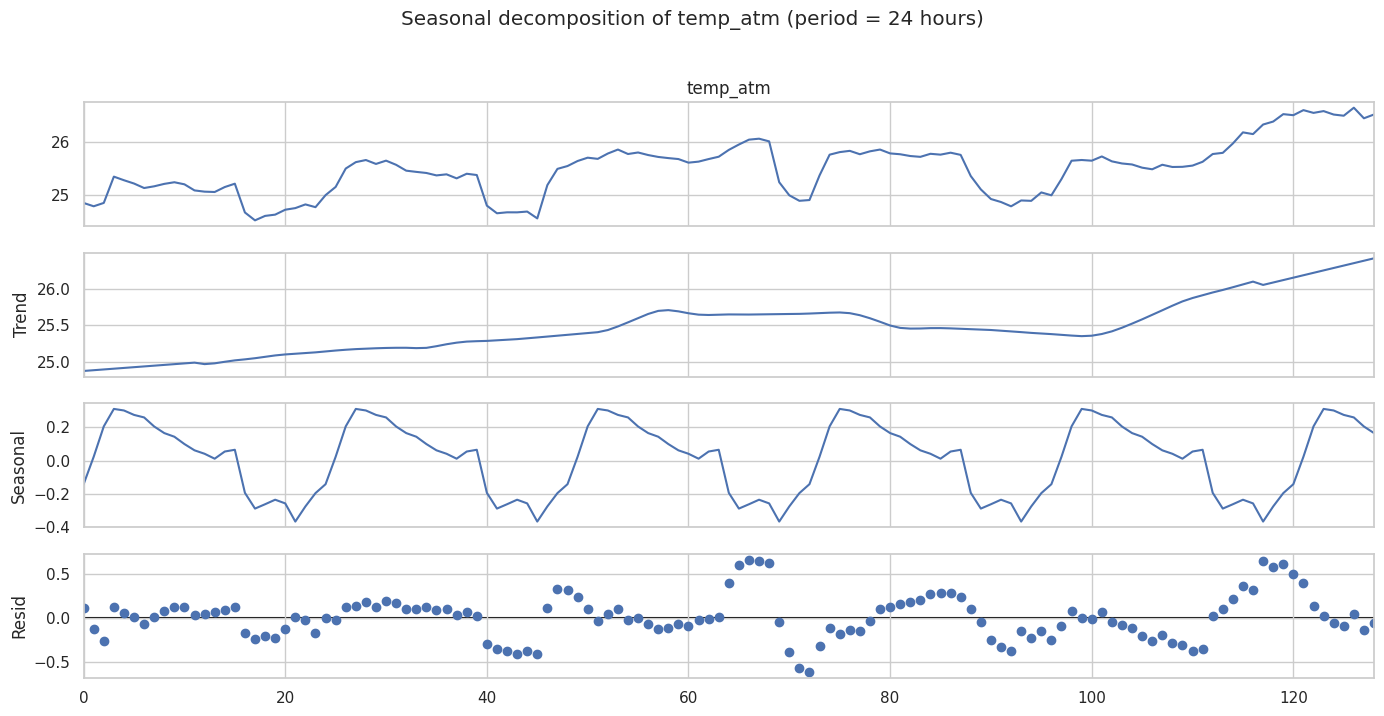

temp_atm: seasonal component explains ≈ 17.3 % of the variance


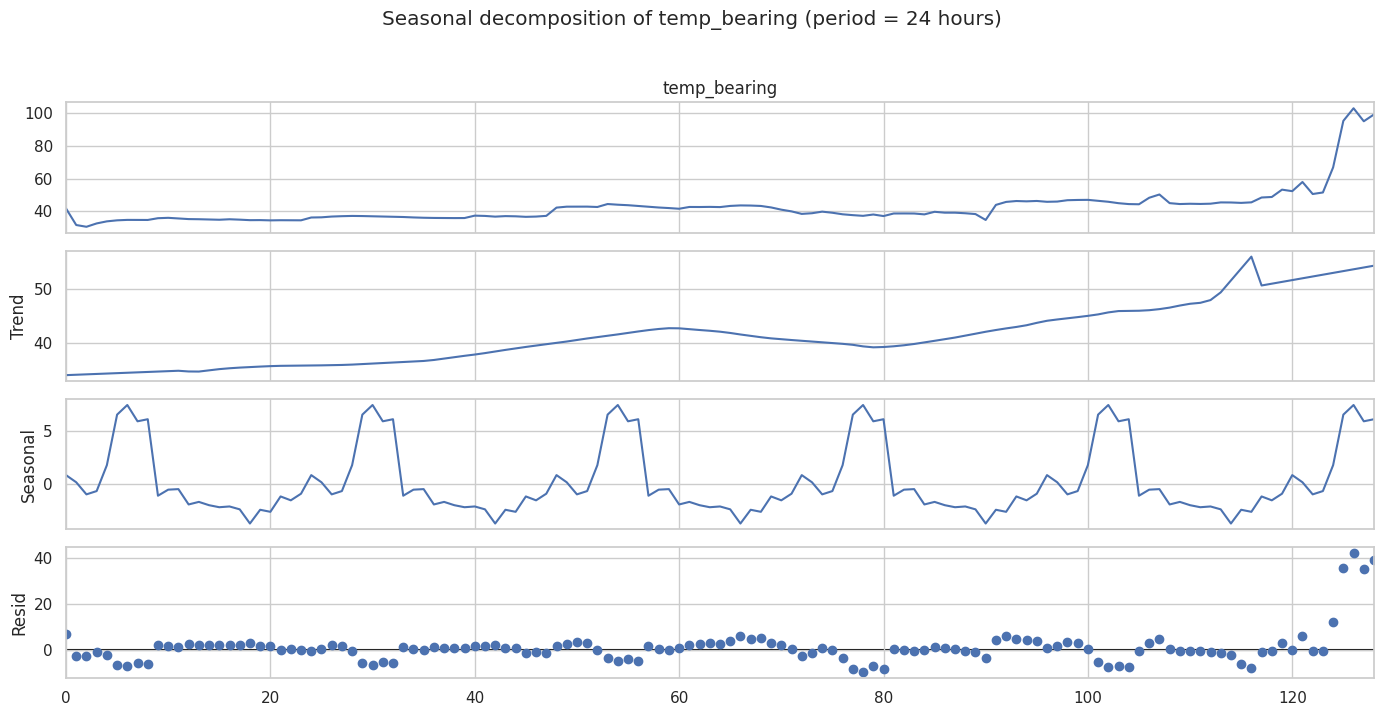

temp_bearing: seasonal component explains ≈ 8.2 % of the variance


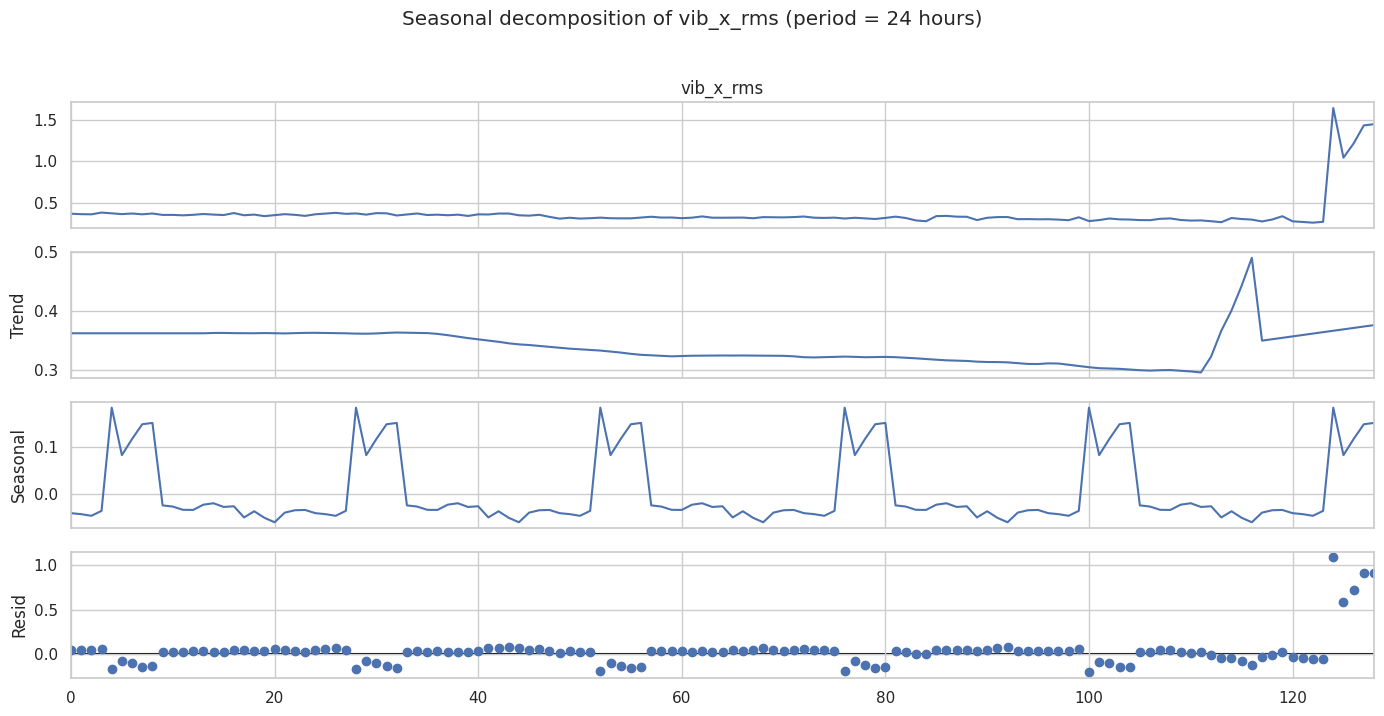

vib_x_rms: seasonal component explains ≈ 13.6 % of the variance


,Kruskal-Wallis H,p-value,daily cycle (α=0.05),peak-to-peak daily amplitude,warmest/highest clock hour
series,,,,,
temp_atm,37.8984,0.0261,True,0.6417,20
temp_bearing,20.2512,0.6267,False,4.2862,17
temp_rise,19.5879,0.6666,False,4.2093,17
vib_x_rms,16.2874,0.8427,False,0.0200,11
vib_y_rms,18.8834,0.7080,False,0.0888,12


,ADF stat,p-value,stationary (α=0.05)
series,,,
vib_x_rms,-1.2017,0.6729,False
vib_x_kurt,-2.1620,0.2203,False
temp_bearing,2.8152,1.0000,False
temp_rise,2.7079,0.9991,False
temp_atm,-2.4776,0.1210,False


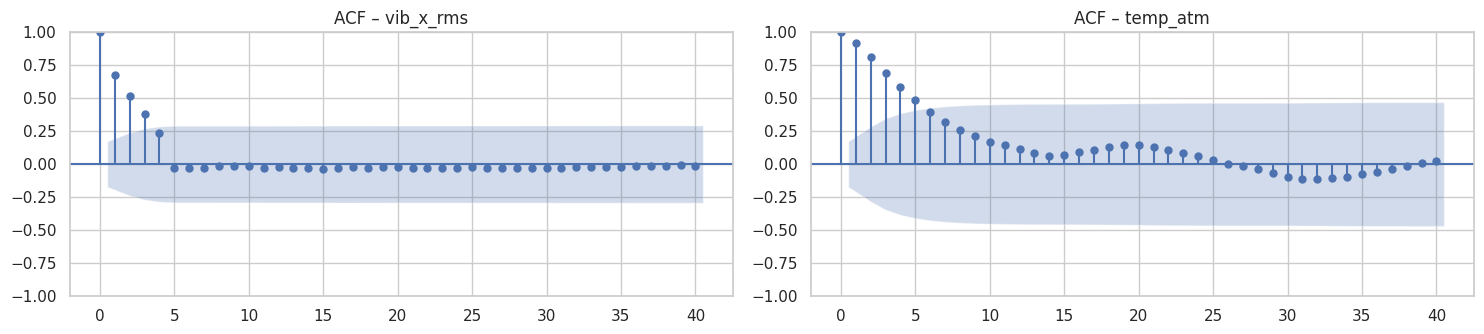

In [ ]:
PERIOD = 24
for col in ['temp_atm', 'temp_bearing', 'vib_x_rms']:
    if len(df) >= 2 * PERIOD:
        res = seasonal_decompose(df.set_index('hour')[col], model='additive', period=PERIOD, extrapolate_trend='freq')
        fig = res.plot(); fig.set_size_inches(14, 7)
        fig.suptitle(f'Seasonal decomposition of {col} (period = {PERIOD} {TIME_UNIT}s)', y=1.02)
        plt.tight_layout(); plt.show()
        var_s = np.var(res.seasonal) / np.var(df[col]) * 100
        print(f'{col}: seasonal component explains ≈ {var_s:.1f} % of the variance')

# Statistical test of the daily cycle (Kruskal-Wallis across clock hours on detrended, pre-failure data)
pre = df[df['health_stage'].astype(str) != 'Vibration alarm'].copy()
kw_rows = []
for col in ['temp_atm', 'temp_bearing', 'temp_rise', 'vib_x_rms', 'vib_y_rms']:
    detr = pre[col] - pre[col].rolling(24, center=True, min_periods=12).mean()
    groups = [g_.dropna().values for _, g_ in detr.groupby(pre['clock_hour']) if g_.notna().sum() > 1]
    H, p_ = stats.kruskal(*groups)
    amp = detr.groupby(pre['clock_hour']).mean()
    kw_rows.append({'series': col, 'Kruskal-Wallis H': H, 'p-value': p_, 'daily cycle (α=0.05)': p_ < 0.05,
                    'peak-to-peak daily amplitude': amp.max() - amp.min(),
                    'warmest/highest clock hour': int(amp.idxmax())})
display(pd.DataFrame(kw_rows).set_index('series'))

# Augmented Dickey-Fuller stationarity test (H0: series has a unit root = non-stationary)
adf_rows = []
for col in ['vib_x_rms', 'vib_x_kurt', 'temp_bearing', 'temp_rise', 'temp_atm']:
    stat, p, *_ = adfuller(df[col].dropna(), autolag='AIC')
    adf_rows.append({'series': col, 'ADF stat': stat, 'p-value': p, 'stationary (α=0.05)': p < 0.05})
display(pd.DataFrame(adf_rows).set_index('series'))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
plot_acf(df['vib_x_rms'], lags=min(40, len(df) // 2 - 1), ax=axes[0], title='ACF – vib_x_rms')
plot_acf(df['temp_atm'], lags=min(40, len(df) // 2 - 1), ax=axes[1], title='ACF – temp_atm')
plt.tight_layout(); plt.show()

### 5.2 Prognostic quality of features – monotonicity and trendability
Common prognostics criteria are used to rank features for RUL modeling: **monotonicity** $M=\frac{|\#(\Delta x>0)-\#(\Delta x<0)|}{n-1}$ (computed on the smoothed series) and **trendability** = |Spearman ρ| with time.

,monotonicity,trendability,score
temp_bearing,0.2500,0.8813,0.5656
temp_rise,0.2344,0.8755,0.5549
vib_x_rms,0.0938,0.6484,0.3711
vib_x_p2p,0.0625,0.5677,0.3151
vib_x_peak,0.0469,0.5377,0.2923
vib_x_kurt,0.1094,0.4165,0.2629
vib_x_skew,0.1094,0.3212,0.2153
vib_y_centroid,0.1094,0.2281,0.1687
vib_y_kurt,0.0469,0.2773,0.1621
vib_x_centroid,0.0625,0.1669,0.1147


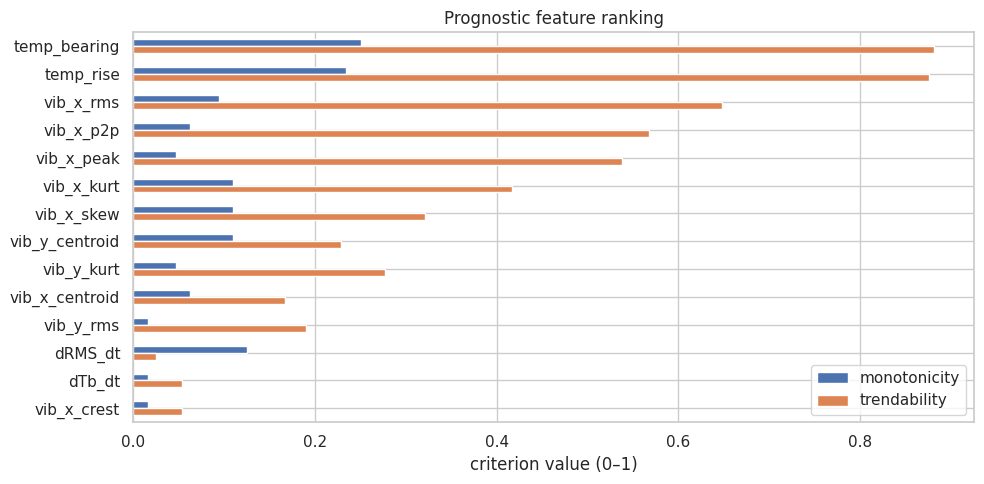

In [ ]:
cands = ['vib_x_rms', 'vib_y_rms', 'vib_x_peak', 'vib_x_p2p', 'vib_x_kurt', 'vib_x_crest',
         'vib_x_skew', 'vib_x_centroid', 'vib_y_kurt', 'vib_y_centroid', 'temp_bearing', 'temp_rise',
         'dTb_dt', 'dRMS_dt']
def monotonicity(s, w=ROLL):
    d = np.diff(s.rolling(w, center=True, min_periods=1).mean())
    return abs((d > 0).sum() - (d < 0).sum()) / (len(d))
rank = pd.DataFrame({'monotonicity': [monotonicity(df[c]) for c in cands],
                     'trendability': [abs(spearmanr(df['hour'], df[c])[0]) for c in cands]}, index=cands)
rank['score'] = rank.mean(axis=1)
rank = rank.sort_values('score', ascending=False)
display(rank)
rank[['monotonicity', 'trendability']].plot(kind='barh', figsize=(10, 5), title='Prognostic feature ranking')
plt.xlabel('criterion value (0–1)'); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### 5.3 Signal-level evolution: waveform, frequency spectrum and envelope spectrum
Raw snippets (1 s, i.e. 1 Hz frequency resolution) from selected hours are compared. Bearing defect frequencies for a 6205 bearing (9 balls, d = 7.94 mm, D = 39.04 mm) at the configured speed are marked on the envelope spectrum – energy at **BPFO/BPFI/BSF** links the vibration increase to a specific defect location (diagnostic insight).

Characteristic frequencies [Hz]: {'BPFO': 106.0, 'BPFI': 160.2, 'BSF': 69.7, 'FTF': 11.8, '1×': 29.6}


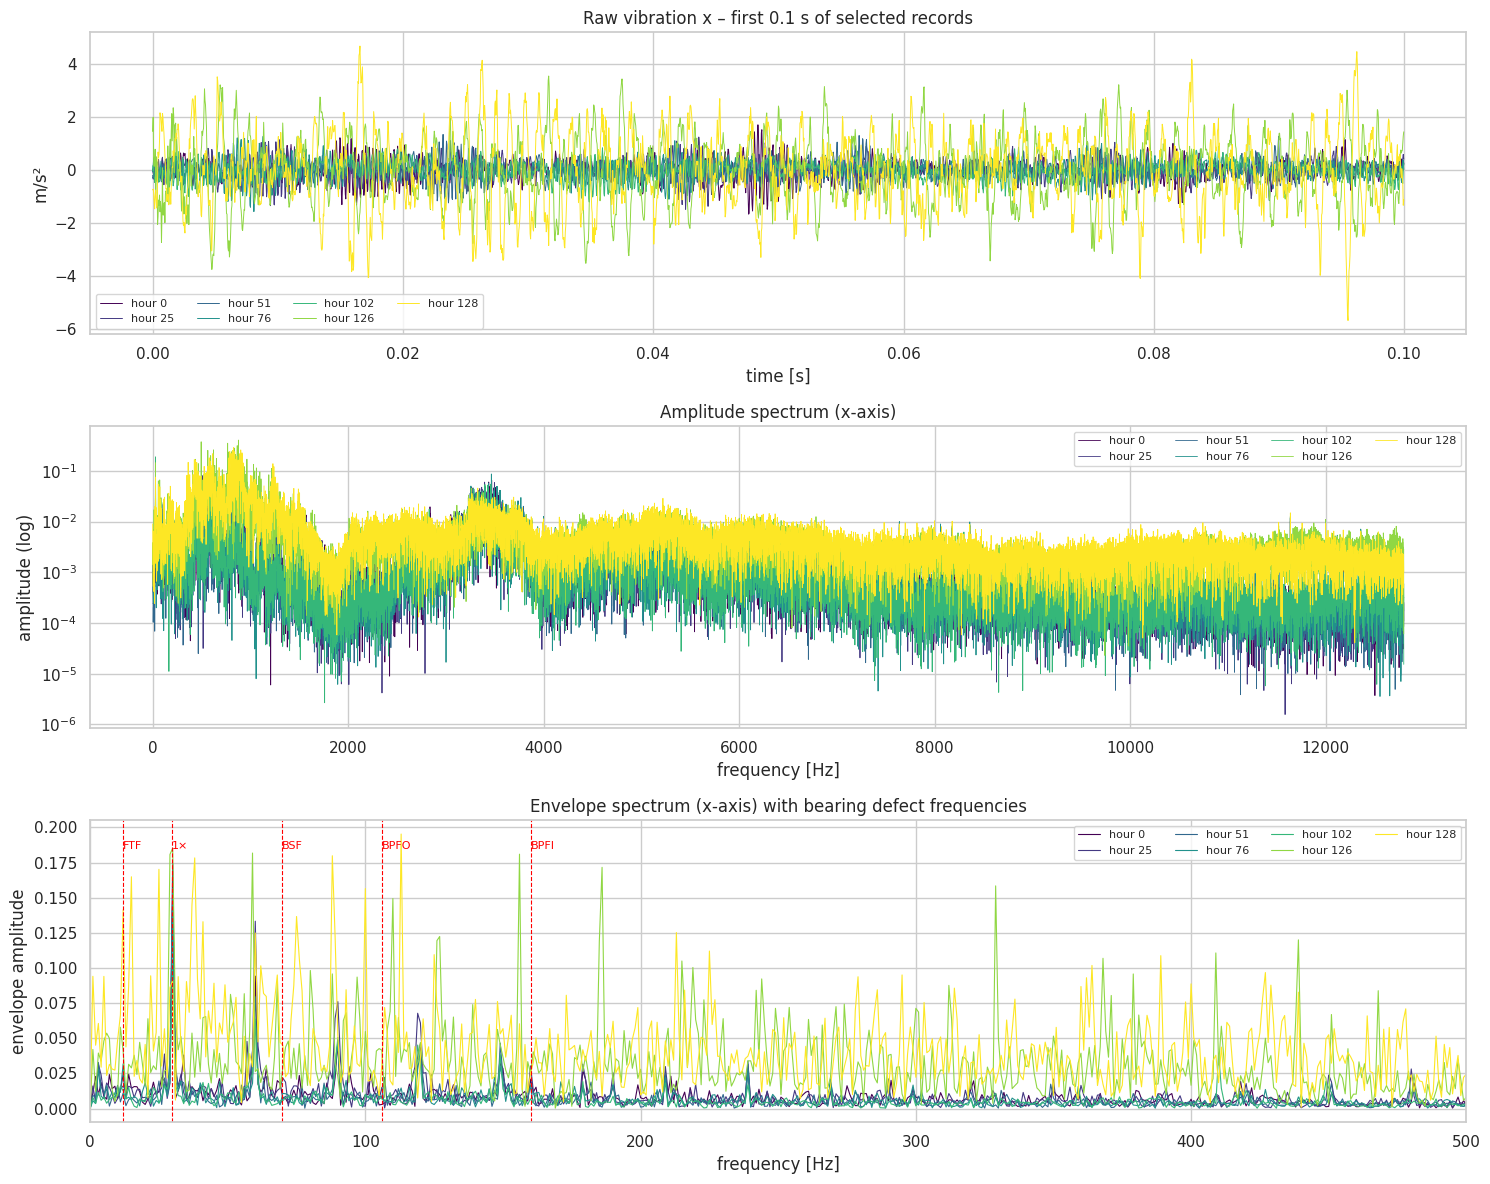

In [ ]:
fr = RPM / 60; n_b, d_b, D_p = 9, 7.94, 39.04
ratio = d_b / D_p
defect_f = {'BPFO': n_b / 2 * fr * (1 - ratio), 'BPFI': n_b / 2 * fr * (1 + ratio),
            'BSF': D_p / (2 * d_b) * fr * (1 - ratio ** 2), 'FTF': fr / 2 * (1 - ratio), '1×': fr}
print('Characteristic frequencies [Hz]:', {k: round(v, 1) for k, v in defect_f.items()})

keys = sorted(snippets)
colors = plt.cm.viridis(np.linspace(0, 1, len(keys)))
fig, axes = plt.subplots(3, 1, figsize=(15, 12))
for c, k in zip(colors, keys):
    x = snippets[k][:, 0].astype(float); x = x - x.mean()
    t = np.arange(len(x)) / FS
    axes[0].plot(t[:2560], x[:2560], color=c, lw=0.7, label=f'{TIME_UNIT} {k}')     # first 0.1 s
    f = np.fft.rfftfreq(len(x), 1 / FS); A = np.abs(np.fft.rfft(x)) / len(x) * 2
    axes[1].semilogy(f[1:], A[1:], color=c, lw=0.6, label=f'{TIME_UNIT} {k}')
    env = np.abs(hilbert(x)); env -= env.mean()
    E = np.abs(np.fft.rfft(env)) / len(env) * 2
    axes[2].plot(f, E, color=c, lw=0.8, label=f'{TIME_UNIT} {k}')
axes[0].set_title('Raw vibration x – first 0.1 s of selected records'); axes[0].set_xlabel('time [s]'); axes[0].set_ylabel(VIB_UNIT)
axes[1].set_title('Amplitude spectrum (x-axis)'); axes[1].set_xlabel('frequency [Hz]'); axes[1].set_ylabel('amplitude (log)')
axes[2].set_xlim(0, 500); axes[2].set_title('Envelope spectrum (x-axis) with bearing defect frequencies')
axes[2].set_xlabel('frequency [Hz]'); axes[2].set_ylabel('envelope amplitude')
for name, fq in defect_f.items():
    axes[2].axvline(fq, color='red', ls='--', lw=0.8); axes[2].text(fq, axes[2].get_ylim()[1] * 0.9, name, color='red', fontsize=8)
for ax in axes: ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

#### 📝 Key findings – time-series behaviour
* **Vibration: long flat (slightly decreasing) phase, then abrupt failure.** Mean RMS x per 8-h block: ≈ 0.37 m/s² (hours 0–47) → ≈ 0.32 (48–95) → ≈ 0.30 (96–119) → **0.80 (120–127, +167 %)** → 1.44 (hour 128). The slow 20 % decrease over the first 120 h is consistent with **running-in** (surface smoothing and lubricant redistribution); the vibration alarm (sustained from hour 124) gives only **4 hours** of warning.
* **Temperature: step-wise rise long before the vibration alarm.** Mean bearing temperature per block: ≈ 34–37 °C (hours 0–47) → ≈ 43 °C (from hour 48) → ≈ 38–39 °C (hours 72–87) → ≈ 46–47 °C (hours 96–119) → 72 °C (120–127) → 99 °C (hour 128). The temperature rise above ambient doubles from ≈ 9–10 °C to ≈ 20–21 °C before vibration reacts; the thermal warning is sustained from **hour 48 – 76 hours before the vibration alarm** → **friction/lubrication degradation is visible thermally first**. The test ended when the bearing exceeded 85 °C (hourly mean 103 °C, instantaneous max 108.8 °C) – consistent with the stated termination criterion.
* **Start-up transient:** hour 0 shows 41.8 °C followed by 31.7 °C in hour 1 – a start-up effect that must be excluded from baselines.
* **Seasonality:** `seasonal_decompose` assigns 17.3 % (ambient), 8.2 % (bearing temp.) and 13.6 % (RMS x) of the variance to a 24-h component, but the **Kruskal–Wallis test** shows that only the **ambient temperature has a statistically real daily cycle** (H = 37.9, p = 0.026; amplitude ≈ 0.64 °C, warmest ≈ 20:00). Bearing temperature (p = 0.63), temperature rise (p = 0.67) and vibration RMS x/y (p = 0.84 / 0.71) show **no significant daily cycle** – their "seasonal" components are artefacts of the decomposition (step changes and noise). → The small daily ambient cycle is a noise factor that is removed by using the **temperature rise**; no de-seasonalisation of the bearing indicators is needed.
* **Stationarity (ADF):** all series are **non-stationary** (p = 0.67 RMS x, 0.22 kurtosis, 1.00 bearing temp., 0.999 temp. rise, 0.12 ambient) – they contain trends/level shifts → time-ordered splits; differencing or trend-aware models; no random shuffling.
* **Feature ranking (monotonicity + trendability):** bearing temperature (0.25 / 0.88) and temperature rise (0.23 / 0.88) rank first, RMS x third (0.09 / 0.65), followed by p2p, peak and kurtosis; crest factor and the raw hourly slopes rank last. All monotonicity values are low (≤ 0.25) → indicators fluctuate hour to hour; **smoothing is required** before RUL modeling.
* **Spectra:** all hours share a resonance band around 3.2–3.6 kHz (structural/sensor-mount resonance, explains the ≈ 3.9 kHz centroid). In hours 126–128 the whole spectrum rises by about one order of magnitude (strongest below ≈ 1.5 kHz) and the raw waveform amplitude grows from ≈ ±1.5 to ±4–6 m/s². The late-life **envelope spectrum** is dominated by the shaft frequency 1× ≈ 29.6 Hz and its harmonics (≈ 59, 89 Hz) plus peaks near 110 Hz and 150–157 Hz, i.e. *close to* but not exactly at BPFO (106 Hz) and BPFI (160 Hz). With 1-s snippets and speed uncertainty this is **not conclusive** for the defect location; a physical inspection or longer high-resolution envelope analysis would be needed.
* *Implications:* time-ordered split; piece-wise linear RUL target (constant early RUL, decreasing after the thermal warning); smoothed temperature-rise and vibration features; separate detection logic for the abrupt final phase.

## 6. Dashboard-Style Figure – Bearing Health Overview
A single figure combining the key EDA results (matplotlib `subplots` + `GridSpec`), suitable for a maintenance review meeting.

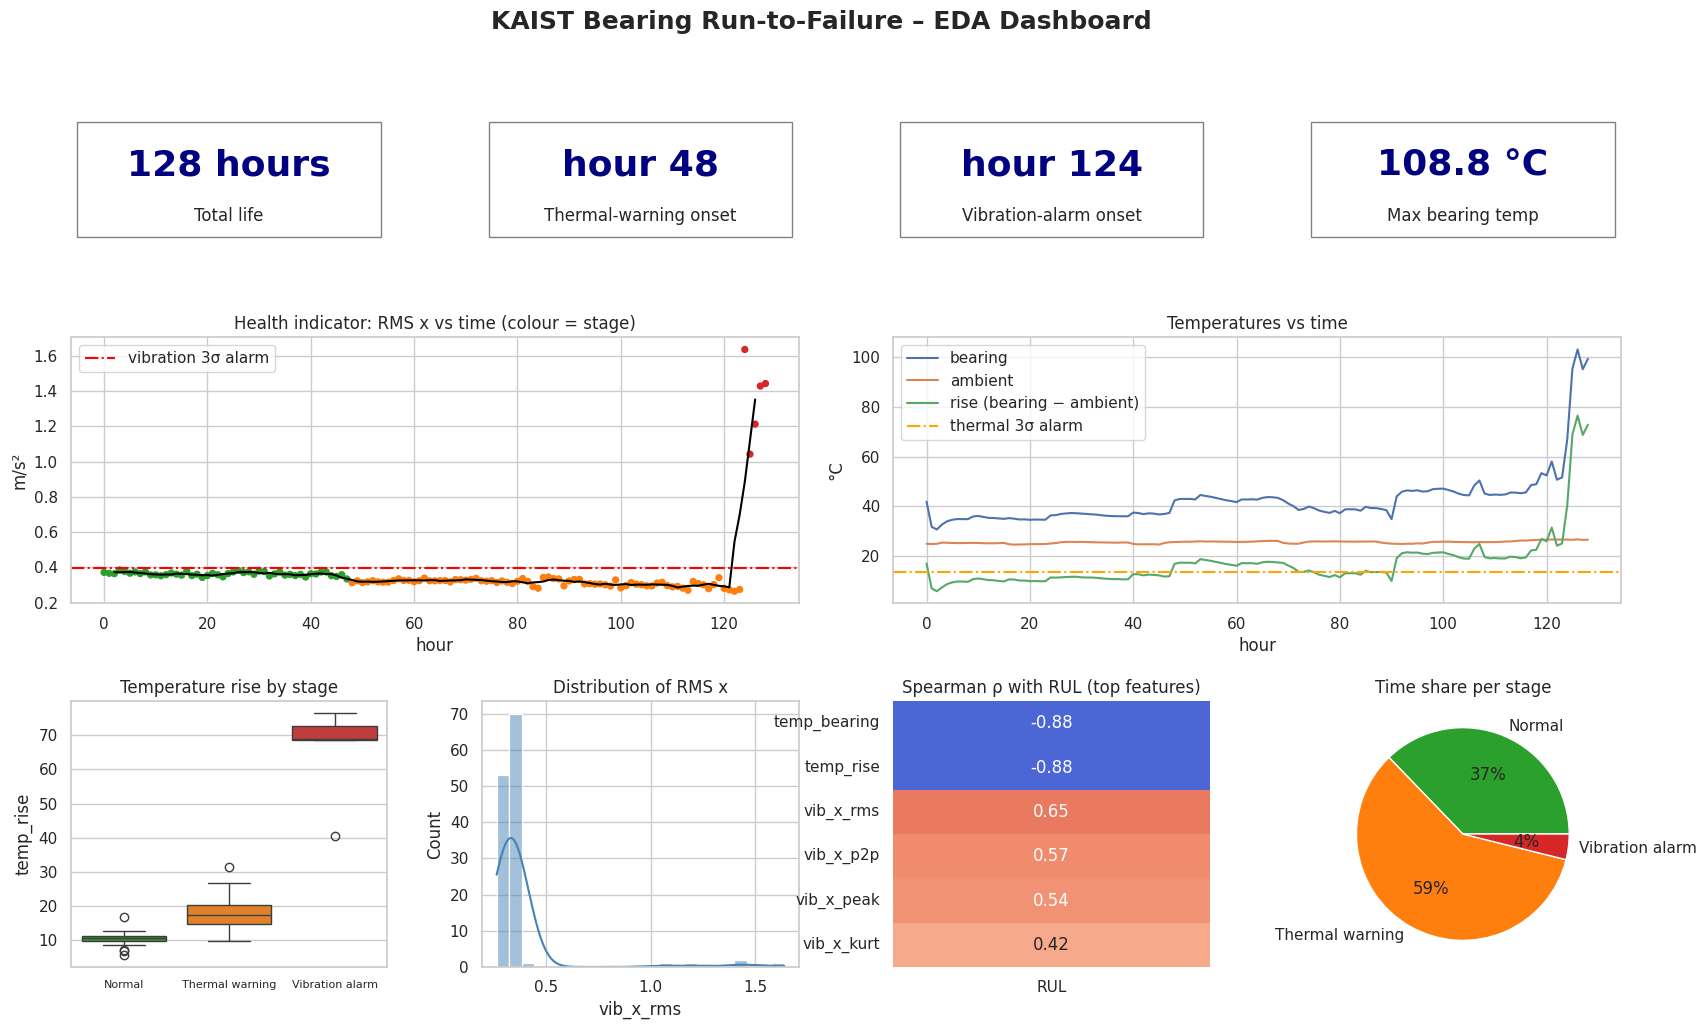

In [ ]:
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(20, 11))
gs = GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.3, height_ratios=[0.45, 1, 1])
stage_col = df['health_stage'].astype(str).map(STAGE_COL)

# KPI tiles
kpis = [('Total life', f"{life:.0f} {TIME_UNIT}s"),
        ('Thermal-warning onset', f"{TIME_UNIT} {temp_onset}" if temp_onset is not None else '–'),
        ('Vibration-alarm onset', f"{TIME_UNIT} {onset}" if onset is not None else '–'),
        ('Max bearing temp', f"{df['temp_bearing_max'].max():.1f} °C")]
for i, (k, v) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis('off')
    ax.text(0.5, 0.62, v, ha='center', va='center', fontsize=26, weight='bold', color='navy')
    ax.text(0.5, 0.2, k, ha='center', va='center', fontsize=12)
    ax.add_patch(plt.Rectangle((0.02, 0.02), 0.96, 0.96, fill=False, transform=ax.transAxes, color='gray'))

ax = fig.add_subplot(gs[1, :2])
ax.scatter(df['hour'], df['vib_x_rms'], c=stage_col, s=18)
ax.plot(df['hour'], df['vib_x_rms'].rolling(ROLL, center=True).mean(), color='black')
ax.axhline(ALARM, color='red', ls='-.', label='vibration 3σ alarm'); ax.legend()
ax.set_title('Health indicator: RMS x vs time (colour = stage)'); ax.set_xlabel(TIME_UNIT); ax.set_ylabel(VIB_UNIT)

ax = fig.add_subplot(gs[1, 2:])
ax.plot(df['hour'], df['temp_bearing'], label='bearing'); ax.plot(df['hour'], df['temp_atm'], label='ambient')
ax.plot(df['hour'], df['temp_rise'], label='rise (bearing − ambient)')
ax.axhline(TEMP_ALARM, color='orange', ls='-.', label='thermal 3σ alarm')
ax.set_title('Temperatures vs time'); ax.set_xlabel(TIME_UNIT); ax.set_ylabel('°C'); ax.legend()

ax = fig.add_subplot(gs[2, 0])
sns.boxplot(data=df, x='health_stage', y='temp_rise', order=stage_order, palette=pal, ax=ax)
ax.set_title('Temperature rise by stage'); ax.set_xlabel(''); ax.tick_params(axis='x', labelsize=8)

ax = fig.add_subplot(gs[2, 1])
sns.histplot(df['vib_x_rms'], kde=True, ax=ax, color='steelblue'); ax.set_title('Distribution of RMS x')

ax = fig.add_subplot(gs[2, 2])
top = rank.head(6).index.tolist()
sns.heatmap(df[top + ['RUL']].corr('spearman')[['RUL']].drop('RUL'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, cbar=False)
ax.set_title('Spearman ρ with RUL (top features)')

ax = fig.add_subplot(gs[2, 3])
vc.plot(kind='pie', autopct='%1.0f%%', colors=pal, ax=ax, ylabel=''); ax.set_title('Time share per stage')

fig.suptitle('KAIST Bearing Run-to-Failure – EDA Dashboard', fontsize=18, weight='bold')
plt.show()

**Reading the dashboard:** the KPI row gives the test life and the two alarm onsets (thermal warning vs. vibration alarm) and the maximum bearing temperature; the middle row shows that vibration stays below its 3σ alarm until the last hours while the temperature rise crosses its alarm band much earlier; the bottom row shows the stage separation of the temperature rise, the skewed RMS distribution, the Spearman correlations of the best-ranked features with RUL and the stage imbalance.

## 7. Overall Findings and Implications for the Next Project Phases

| # | Finding (EDA, full 129-hour data) | Implication |
|---|---|---|
| 1 | All 129 files read; 2,000,001 samples each; near-hourly spacing (one 72/46-min irregularity); only ≈ 0.003 % raw values missing; no meaningful duplicates. | Minimal cleaning (interpolate raw gaps); no row deletion. |
| 2 | Hourly outliers occur in hours 120–128 (failure signature) and hour 1 (start-up transient). | Keep them; baseline-referenced alarm limits and robust scaling instead of removal. |
| 3 | All indicators are non-normal (Shapiro p < 0.05); vibration features extremely right-skewed (RMS skew 4.9, kurtosis max 258). | Non-parametric statistics; log/robust scaling. |
| 4 | **Temperature is the best RUL correlate** (ρ ≈ −0.88); vibration RMS slowly *decreases* for ≈ 120 h (Spearman +0.65, Pearson −0.21) and jumps only in the last ≈ 5 h. | Temperature rise is the key prognostic feature; vibration features mainly confirm the final failure phase. |
| 5 | Thermal warning at hour 48, vibration alarm at hour 124 → 76 h earlier warning from temperature; vibration alone gives 4 h. Stages: 48 / 76 / 5 h. | PM trigger (Eq. 4) must use temperature features to obtain a usable lead time $H$. |
| 6 | Ambient coefficient falls from 9.05 to 3.24 °C/°C when time is added (Model B2, R² 0.834) → time confound; only ambient temperature has a significant daily cycle (Kruskal–Wallis p = 0.026). | Use $T_b-T_{amb}$ and a time/trend feature; no de-seasonalisation of bearing indicators needed. |
| 7 | Linear RUL~RMS model explains 4 % (R² = 0.044); residuals autocorrelated (DW = 0.02); series non-stationary (ADF). | Non-linear primary model (RF/GBM) vs. linear baseline; time-ordered split; piece-wise RUL target. |
| 8 | Redundant pairs (T_b–rise 0.995, peak–p2p 0.975); hourly slopes and crest factor uninformative without smoothing. | Drop redundant features; compute slopes on smoothed series. |
| 9 | Single bearing → no population lifetime distribution. | Windowing augmentation + 2nd dataset (XJTU-SY / PRONOSTIA) for Weibull/Kaplan–Meier and cross-bearing validation. |

**Planned modeling pipeline (consistent with Assignment 2, updated by the EDA):** 1-s windows (augmentation) → condition vector $x(t)$, Eq. (2), with **smoothed** slopes → robust scaling → **primary model: Random Forest / gradient boosting** (quantile loss or forest quantiles give the 90 % lower bound $LB_{90\%}$) vs. **baseline: linear regression** → **MAE, RMSE, R²** (+ error per health stage) on a **time-ordered split** → PM trigger $t_{PM}=\min\{t: LB_{90\%}[\widehat{RUL}(t)]\le H\}$, Eq. (4), compared with fixed PM intervals (retained useful life vs. failure risk).

## 8. AI Use and Reflection

* **Where AI was used:** a generative AI assistant (Claude) was used to draft the notebook structure, write helper code for streaming the 129 CSV files from the ZIP, and suggest bearing-prognostics condition indicators and plot layouts.
* **Verification:** we ran every cell on the full dataset, checked the computed RMS/kurtosis values against a manual NumPy calculation for one hour, compared the bearing defect frequencies with the standard formulas, and checked the dataset facts (sampling rate, loads, termination criterion) against the Mendeley dataset page.
* **Modifications / rejections:** the first AI-drafted interpretations assumed the common textbook pattern (vibration RMS increasing gradually with wear). The full-data run **contradicted this** – RMS slowly decreased and jumped only in the last hours, and the vibration-only health-stage rule left the "degrading" class empty. We **rejected** those statements, redefined the stages with a thermal + vibration alarm, added the Kruskal–Wallis seasonality test (because `seasonal_decompose` always produces a seasonal component) and Model B2 (time confound), and rewrote every finding with the measured numbers. A second full run was checked line-by-line against the text; this revealed further corrections (irregular file spacing, the start-up outlier at hour 1, and that only the ambient temperature has a significant daily cycle).
* **Reflection:** _[edit: what the group learned and which parts were done independently]_.

### References
1. R. Zhu, X. Zhang, Q. Huang, S. Li, Q. Fu, "Predicting the Remaining Life of Centrifugal Pump Bearings Using the KPCA-LSTM Algorithm," *Energies*, 17(16), 4167, 2024. doi:10.3390/en17164167.
2. W. Jung, S. Yun, J. Kim, Y.-H. Park, "Vibration, and temperature run-to-failure dataset of ball bearing for prognostics," *Data in Brief*, 54, 110403, 2024. doi:10.1016/j.dib.2024.110403.
3. W. Jung, S. Yun, J. Kim, Y.-H. Park, "Ball Bearing Vibration, and Temperature Run-to-Failure Dataset," Mendeley Data, v6, 2024. doi:10.17632/5hcdd3tdvb.6.
4. Siemens AG, *The True Cost of Downtime 2024*, 2024.
5. ISE 518 course notebooks: `10_Descriptive_analytics/EDA.ipynb`, `TimeSeries_Analysis.ipynb`, `Anomaly_Detection.ipynb` (Dr. A. Khamis, KFUPM).